### imports

In [56]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)
from sklearn.metrics import r2_score, mean_squared_error
import umap.umap_ as umap

from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d


In [17]:
from functions_experimental_data_Bräckleinexp import *

# def conv_spikes(array, pos1, pos2, fs, window_duration=0.3):
#     window_samples = int(round(window_duration * fs))
#     hanning_window = windows.hann(window_samples)
#     hanning_window /= np.sum(hanning_window)  
#     smoothed_spike_array1 = convolve(array[pos1, :], hanning_window, mode='same') * fs
#     smoothed_spike_array2 = convolve(array[pos2, :], hanning_window, mode='same') * fs
#     return smoothed_spike_array1, smoothed_spike_array2

Fsamp = 2048  # Sampling frequency


## firing rates

In [18]:
# folder_path = '/Users/nmt121/Desktop/DATA/S1'

# pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.pkl')], key=lambda x: (extract_day(x), extract_trial(x)))

# plot_firing_rates(folder_path, pkl_files, Fsamp)


## load all sessions

In [2]:

session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_12.pkl', 'E3_MB07_Day09High_13.pkl',
        'E3_MB07_Day09High_14.pkl', 'E3_MB07_Day09High_18.pkl', 'E3_MB07_Day09High_19.pkl',
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
        'E3_MB07_Day09High_23.pkl', 'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
        'E3_MB07_Day09High_3.pkl', 'E3_MB07_Day09High_30.pkl', 'E3_MB07_Day09High_4.pkl',
        'E3_MB07_Day09High_6.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}






## Important functions for predicting spikes of neuron X with rest of spikes

In [2]:
def load_and_preprocess(file, bin_size_ms):
    """Load a single trial and preprocess."""
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    
    data_MU = np.array(data['MU'].tolist())  
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, data_MU.shape[1], bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)  

    return smoothed_spikes.T, data

def create_glm_data(spike_data, history_bins, target_idx):
    """Create X (predictors) and Y (target) for GLM while ignoring neurons that never spike."""
    num_timebins, num_neurons = spike_data.shape
    
    # Identify neurons that spike more than 10 times
    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]
    
    if target_idx not in active_neurons:
        return None, None  # If the target neuron is inactive, return None to skip trial
    
    X_list, Y_list = [], []
    
    for t in range(history_bins, num_timebins):
        # Exclude neurons that never spike + target neuron itself from predictors
        X_t = np.hstack([
            spike_data[t - h, np.logical_and(
                np.arange(num_neurons) != target_idx,  
                np.isin(np.arange(num_neurons), active_neurons)
            )]
            for h in range(1, history_bins + 1)
        ])
        Y_t = spike_data[t, target_idx]  
        X_list.append(X_t)
        Y_list.append(Y_t)
    
    return np.array(X_list), np.array(Y_list)

def compute_pR2(model, X, Y):
    """Compute McFadden's pseudo-R² with improved numerical stability."""
    y_pred = model.predict(X)

    # Prevent log(0) errors by ensuring positive values
    y_pred = np.clip(y_pred, 1e-6, None)  
    Y = np.clip(Y, 1e-6, None)  

    # Prevent errors when all spikes are 0
    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan  # Skip computation if no meaningful prediction is possible
    
    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))  
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))

    # Handle division by zero
    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan  # Skip invalid computations

    return 1 - (deviance_model / deviance_null)


## PREDICTION ONLY WITH SPIKES

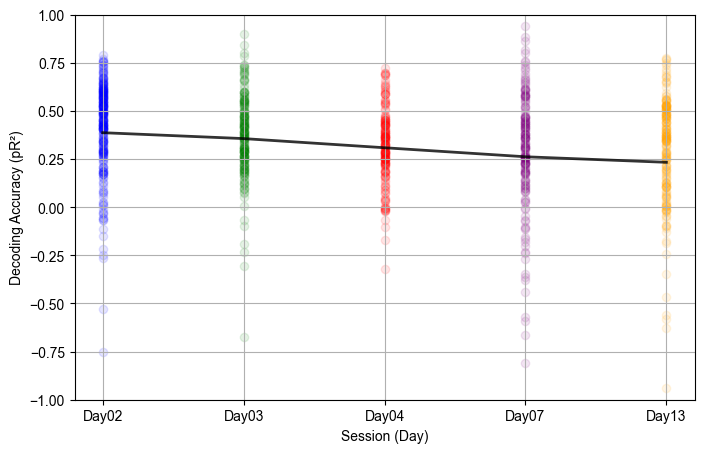

In [19]:
# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S2/'

bin_size_ms = 500  
history_bins = 2

# === TRIAL FILES GROUPED BY SESSION (DAY) ===
session_files = session_files2

# === HYPERPARAMETER GRID ===
alpha_grid = {'alpha': [0.1, 1, 10, 100]}  

# === STORE RESULTS PER SESSION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []  # Store pR² values for the session

    for file in pkl_files:
        glm_data, data = load_and_preprocess(file, bin_size_ms)
        
        num_neurons = glm_data.shape[1]
        for target_idx in range(num_neurons):
            X, Y = create_glm_data(glm_data, history_bins, target_idx)
            
            if X is None or Y is None or np.sum(Y) <20:
                continue  

            X[np.isnan(X)] = 0  
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X)
            
            kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=1000), alpha_grid, cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            
            best_alpha = poisson_cv.best_params_['alpha']

            trial_pR2 = []
            for train_idx, val_idx in kf.split(X_scaled, Y > 0):
                X_train_cv, X_val_cv = X_scaled[train_idx], X_scaled[val_idx]
                Y_train_cv, Y_val_cv = Y[train_idx], Y[val_idx]

                if np.sum(Y_val_cv) < 5:
                    continue  

                poisson_model_cv = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                poisson_model_cv.fit(X_train_cv, Y_train_cv)
                pR2_value = compute_pR2(poisson_model_cv, X_val_cv, Y_val_cv)
                trial_pR2.append(pR2_value)
            
            if len(trial_pR2) > 0:
                session_pR2.extend(trial_pR2)
    
    if len(session_pR2) > 0:
        session_results[session] = session_pR2

# === PLOT RESULTS ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

# Assign colours for sessions
session_colours = {
    "Day02": "blue",
    "Day03": "green",
    "Day04": "red",
    "Day07": "purple",
    "Day13": "orange"
}

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)
    
    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    # Scatter plot of individual neurons
    x_positions = np.full(len(pR2_values), idx)  
    plt.scatter(x_positions, pR2_values, color=session_colours[session], alpha=0.1)
    
    # Mean ± std error bars
    # plt.errorbar(idx, mean_pR2, yerr=std_pR2, fmt='o', color='black', capsize=5)

# === Gaussian Smoothing of Session Means ===
x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)  # Adjust sigma for smoothness
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# X-axis labels
plt.xticks(range(len(session_labels)), session_labels)

# Labels and title
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1,1])
plt.grid(True)

plt.show()

# plt.bar(np.arange(1, len(session_means) + 1), session_means, yerr=session_stds, capsize=5, color=[session_colours[s] for s in session_labels])


## TAKE TRIALS PR2(SPIKE+FORCE)>PR2(FORCE) AND BOOTSTRAPPING

In [5]:
def preprocess_trial(file, bin_size_ms):
    """Load a single trial, preprocess spikes and force data, and fix shape mismatches."""
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    # Extract and reshape force data
    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()

    # Extract and check spike data
    data_MU = np.array(data['MU'].tolist())  # Shape (neurons, time)

    # Ensure force and spikes have the same number of time points
    min_length = min(force.shape[0], data_MU.shape[1])
    force = force[:min_length]
    data_MU = data_MU[:, :min_length]

    # Compute number of bins
    num_bins = min_length // bin_size_ms
    if num_bins == 0:
        print(f"Skipping {file}: Not enough time points for binning.")
        return None, None

    # Bin spikes
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_ms, bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)

    # Bin force (mean within bins)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_ms], np.arange(0, num_bins * bin_size_ms, bin_size_ms)) / bin_size_ms

    return smoothed_spikes[:, :num_bins].T, binned_force[:num_bins]

# === FUNCTION TO NORMALIZE FORCE PER SESSION ===
def normalize_force_per_session(force_list, spike_list):
    """Normalize force within a session and scale it to match spike magnitude."""
    if len(force_list) == 0:
        return []

    # Normalize force within the session using MinMax scaling
    scaler = MinMaxScaler(feature_range=(0, 1))
    concatenated_forces = np.concatenate(force_list).reshape(-1, 1)
    scaler.fit(concatenated_forces)

    # Find mean spike count per neuron (for scaling)
    avg_spike_rate = np.mean([np.mean(spikes) for spikes in spike_list])  

    # Scale force to match spike range
    return [(scaler.transform(f.reshape(-1, 1)).flatten()) * avg_spike_rate for f in force_list]

# === FUNCTION TO PREPARE GLM INPUT DATA ===
def prepare_glm_data(spike_data, force_data, history_bins, target_idx):
    """Prepare GLM input data (X) and output (Y) while incorporating spike history and force."""
    num_timebins, num_neurons = spike_data.shape

    # Identify neurons that spike at least 10 times
    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]
    
    if target_idx not in active_neurons:
        return None, None  # Skip if the target neuron is inactive
    
    X_list, Y_list = [], []

    for t in range(history_bins, num_timebins):
        # Collect past spike history from active neurons, excluding the target neuron
        history = np.hstack([
            spike_data[t - h, np.logical_and(
                np.arange(num_neurons) != target_idx,  
                np.isin(np.arange(num_neurons), active_neurons)
            )]
            for h in range(1, history_bins + 1)
        ])
        
        # Include the current force value as a predictor
        force_t = force_data[t]  

        # Append to dataset
        X_list.append(np.hstack([history, force_t]))  
        Y_list.append(spike_data[t, target_idx])  

    return np.array(X_list), np.array(Y_list)

# === FUNCTION TO COMPUTE PSEUDO-R² ===
def compute_pseudo_r2(glm_model, X, Y):
    """Compute McFadden's pseudo-R² while preventing numerical errors."""
    y_pred = glm_model.predict(X)
    y_pred = np.clip(y_pred, 1e-6, None)  
    Y = np.clip(Y, 1e-6, None)  

    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan  
    
    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))  
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))

    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan  

    return 1 - (deviance_model / deviance_null)

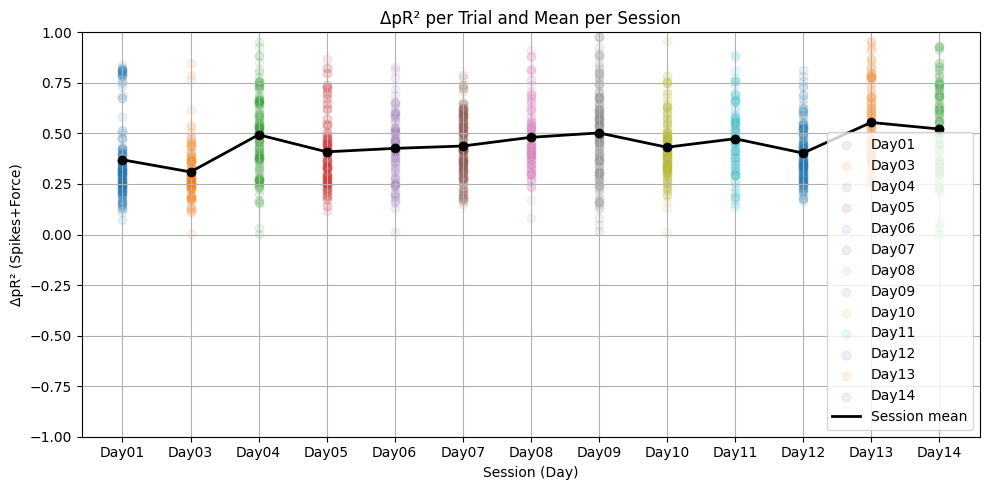

In [ ]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S1/'
bin_size_ms = 500
history_bins = 2
n_bootstrap = 1000

session_files = session_files1


# === FUNCTION TO COMPUTE PSEUDO-R² ===
def compute_pseudo_r2(glm_model, X, Y):
    y_pred = glm_model.predict(X)
    y_pred = np.clip(y_pred, 1e-6, None)
    Y = np.clip(Y, 1e-6, None)

    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan

    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))

    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan

    return 1 - (deviance_model / deviance_null)

# === FUNCTION TO PERFORM BOOTSTRAP ANALYSIS ===
def bootstrap_pr2_analysis_per_session(session_pR2_spikes_force, session_pR2_force_only, n_bootstrap=1000):
    bootstrap_results = {}
    session_bootstrap_means = {}

    for session in session_pR2_spikes_force.keys():
        pR2_diff = np.array(session_pR2_spikes_force[session]) - np.array(session_pR2_force_only[session])
        significant_trials = pR2_diff > 0
        pR2_diff_significant = pR2_diff[significant_trials]

        if len(pR2_diff_significant) == 0:
            bootstrap_results[session] = {"Error": "No significant trials found."}
            continue

        bootstrap_means = []
        for _ in range(n_bootstrap):
            resampled_trials = np.random.choice(pR2_diff_significant, size=len(pR2_diff_significant), replace=True)
            bootstrap_means.append(np.mean(resampled_trials))

        ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])
        session_bootstrap_means[session] = np.mean(bootstrap_means)

        bootstrap_results[session] = {
            "Mean difference": np.mean(pR2_diff_significant),
            "95% CI lower bound": ci_lower,
            "95% CI upper bound": ci_upper,
            "Number of significant trials": len(pR2_diff_significant)
        }

    return bootstrap_results, session_bootstrap_means

# === PREPROCESSING FUNCTIONS ===
def preprocess_trial(file, bin_size_ms):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()

    data_MU = np.array(data['MU'].tolist())

    min_length = min(force.shape[0], data_MU.shape[1])
    force = force[:min_length]
    data_MU = data_MU[:, :min_length]

    num_bins = min_length // bin_size_ms
    if num_bins == 0:
        print(f"Skipping {file}: Not enough time points for binning.")
        return None, None

    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_ms, bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)

    binned_force = np.add.reduceat(force[:num_bins * bin_size_ms], np.arange(0, num_bins * bin_size_ms, bin_size_ms)) / bin_size_ms

    return smoothed_spikes[:, :num_bins].T, binned_force[:num_bins]

def prepare_glm_data(spike_data, force_data, history_bins, target_idx):
    num_timebins, num_neurons = spike_data.shape
    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]

    if target_idx not in active_neurons:
        return None, None

    X_list, Y_list = [], []

    for t in range(history_bins, num_timebins):
        history = np.hstack([
            spike_data[t - h, np.logical_and(
                np.arange(num_neurons) != target_idx,
                np.isin(np.arange(num_neurons), active_neurons)
            )]
            for h in range(1, history_bins + 1)
        ])
        force_t = force_data[t]
        X_list.append(np.hstack([history, force_t]))
        Y_list.append(spike_data[t, target_idx])

    return np.array(X_list), np.array(Y_list)

# === MAIN ANALYSIS LOOP ===
session_results = {}
bootstrap_results = {}
session_pR2_spikes_force = {}
session_pR2_force_only = {}



for session, pkl_files in session_files.items():
    spikes_force_list = []
    force_only_list = []

    for file in pkl_files:
        spikes, force = preprocess_trial(file, bin_size_ms)
        if spikes is None or force is None:
            continue

        num_neurons = spikes.shape[1]
        for target_idx in range(num_neurons):
            X, Y = prepare_glm_data(spikes, force, history_bins, target_idx)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            X[np.isnan(X)] = 0
            X_scaled = StandardScaler().fit_transform(X)

            kf = KFold(n_splits=10, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=500), {'alpha': [0.1, 1, 10, 100, 1000]},
                                      cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            best_alpha = poisson_cv.best_params_['alpha']

            model_full = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
            model_full.fit(X_scaled, Y)
            pR2_spikes_force = compute_pseudo_r2(model_full, X_scaled, Y)
            spikes_force_list.append(pR2_spikes_force)

            model_force = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
            model_force.fit(X_scaled[:, -1].reshape(-1, 1), Y)
            pR2_force_only = compute_pseudo_r2(model_force, X_scaled[:, -1].reshape(-1, 1), Y)
            force_only_list.append(pR2_force_only)

    if spikes_force_list and force_only_list:
        session_pR2_spikes_force[session] = spikes_force_list
        session_pR2_force_only[session] = force_only_list

# Run bootstrap
bootstrap_results, session_bootstrap_means = bootstrap_pr2_analysis_per_session(
    session_pR2_spikes_force, session_pR2_force_only, n_bootstrap=n_bootstrap
)

# Store full session results
for session in session_pR2_spikes_force.keys():
    session_results[session] = {
        "pR2_spikes_force": np.array(session_pR2_spikes_force[session]),
        "pR2_force_only": np.array(session_pR2_force_only[session]),
        "pR2_diff": np.array(session_pR2_spikes_force[session]) - np.array(session_pR2_force_only[session])
    }

# === PLOTTING RESULTS ===
plt.figure(figsize=(10, 5))
plt.xlabel("Session (Day)")
plt.ylabel("ΔpR² (Spikes+Force)")
plt.ylim([-1, 1])
plt.grid(True)
plt.title("ΔpR² per Trial and Mean per Session")

session_labels = list(session_results.keys())
session_means = []
session_x_positions = []

for i, session in enumerate(session_labels):
    trial_diffs = session_results[session]["pR2_diff"]
    x_pos = np.full(len(trial_diffs), i)
    plt.scatter(x_pos, trial_diffs, alpha=0.1, label=session)
    session_mean = np.nanmean(trial_diffs)
    session_means.append(session_mean)
    session_x_positions.append(i)
    plt.plot(i, session_mean, 'o', color='black', markersize=6)

plt.plot(session_x_positions, session_means, linestyle='-', color='black', linewidth=2, label='Session mean')
plt.xticks(ticks=range(len(session_labels)), labels=session_labels)
plt.legend()
plt.tight_layout()
plt.show()


## with cv

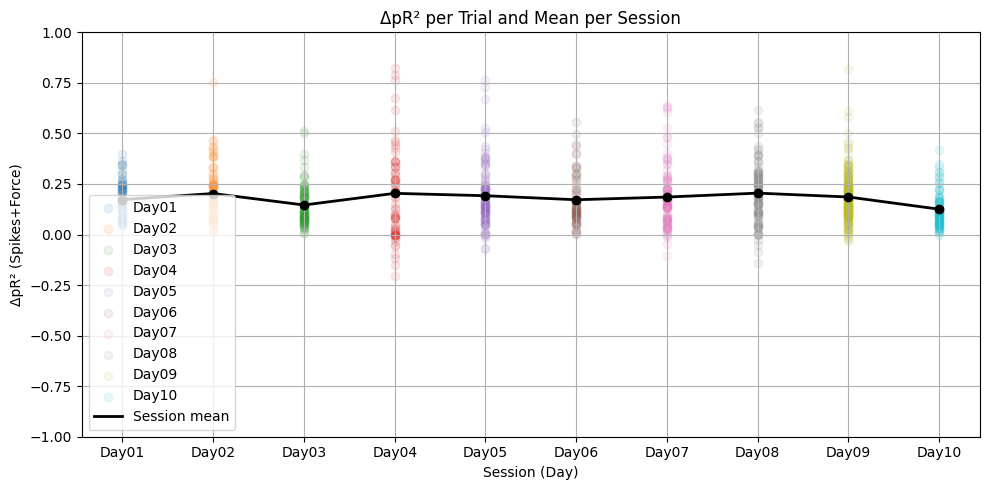

In [105]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import KFold, GridSearchCV, cross_val_predict
from sklearn.linear_model import PoissonRegressor

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S7/'
bin_size_ms = 500
history_bins = 2
n_bootstrap = 1000

# Assuming session_files1 is defined elsewhere in your script
session_files = session_files7

# === FUNCTION TO COMPUTE PSEUDO-R² (for full model prediction on a single dataset) ===
def compute_pseudo_r2(glm_model, X, Y):
    y_pred = glm_model.predict(X)
    y_pred = np.clip(y_pred, 1e-6, None)
    Y = np.clip(Y, 1e-6, None)

    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan

    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))

    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan

    return 1 - (deviance_model / deviance_null)

# === FUNCTION TO COMPUTE PSEUDO-R² FROM CROSS-VALIDATED PREDICTIONS ===
def compute_pseudo_r2_from_cv(Y, Y_pred):
    Y_pred = np.clip(Y_pred, 1e-6, None)
    Y = np.clip(Y, 1e-6, None)
    if np.all(Y == 0) or np.all(Y_pred == 0):
        return np.nan
    deviance_model = 2 * np.sum(Y * np.log(Y / Y_pred) - (Y - Y_pred))
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))
    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan
    return 1 - (deviance_model / deviance_null)

# === FUNCTION TO PERFORM BOOTSTRAP ANALYSIS ===
def bootstrap_pr2_analysis_per_session(session_pR2_spikes_force, session_pR2_force_only, n_bootstrap=1000):
    bootstrap_results = {}
    session_bootstrap_means = {}

    for session in session_pR2_spikes_force.keys():
        pR2_diff = np.array(session_pR2_spikes_force[session]) - np.array(session_pR2_force_only[session])
        significant_trials = pR2_diff > 0
        pR2_diff_significant = pR2_diff[significant_trials]

        if len(pR2_diff_significant) == 0:
            bootstrap_results[session] = {"Error": "No significant trials found."}
            continue

        bootstrap_means = []
        for _ in range(n_bootstrap):
            resampled_trials = np.random.choice(pR2_diff_significant, size=len(pR2_diff_significant), replace=True)
            bootstrap_means.append(np.mean(resampled_trials))

        ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])
        session_bootstrap_means[session] = np.mean(bootstrap_means)

        bootstrap_results[session] = {
            "Mean difference": np.mean(pR2_diff_significant),
            "95% CI lower bound": ci_lower,
            "95% CI upper bound": ci_upper,
            "Number of significant trials": len(pR2_diff_significant)
        }

    return bootstrap_results, session_bootstrap_means

# === PREPROCESSING FUNCTIONS ===
def preprocess_trial(file, bin_size_ms):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()

    data_MU = np.array(data['MU'].tolist())

    min_length = min(force.shape[0], data_MU.shape[1])
    force = force[:min_length]
    data_MU = data_MU[:, :min_length]

    num_bins = min_length // bin_size_ms
    if num_bins == 0:
        print(f"Skipping {file}: Not enough time points for binning.")
        return None, None

    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_ms, bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)

    binned_force = np.add.reduceat(force[:num_bins * bin_size_ms], np.arange(0, num_bins * bin_size_ms, bin_size_ms)) / bin_size_ms

    return smoothed_spikes[:, :num_bins].T, binned_force[:num_bins]

def prepare_glm_data(spike_data, force_data, history_bins, target_idx):
    num_timebins, num_neurons = spike_data.shape
    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]

    if target_idx not in active_neurons:
        return None, None

    X_list, Y_list = [], []

    for t in range(history_bins, num_timebins):
        history = np.hstack([
            spike_data[t - h, np.logical_and(
                np.arange(num_neurons) != target_idx,
                np.isin(np.arange(num_neurons), active_neurons)
            )]
            for h in range(1, history_bins + 1)
        ])
        force_t = force_data[t]
        X_list.append(np.hstack([history, force_t]))
        Y_list.append(spike_data[t, target_idx])

    return np.array(X_list), np.array(Y_list)

# === MAIN ANALYSIS LOOP ===
session_results = {}
bootstrap_results = {}
session_pR2_spikes_force = {}
session_pR2_force_only = {}

# Set up KFold objects for grid search (10 folds) and prediction (5 folds)
kf_grid = KFold(n_splits=10, shuffle=True, random_state=42)
kf_pred = KFold(n_splits=10, shuffle=True, random_state=42)

for session, pkl_files in session_files.items():
    spikes_force_list = []
    force_only_list = []

    for file in pkl_files:
        spikes, force = preprocess_trial(file, bin_size_ms)
        if spikes is None or force is None:
            continue

        num_neurons = spikes.shape[1]
        for target_idx in range(num_neurons):
            X, Y = prepare_glm_data(spikes, force, history_bins, target_idx)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            # Replace any NaN values in X and scale features
            X[np.isnan(X)] = 0
            X_scaled = StandardScaler().fit_transform(X)

            # Use GridSearchCV with 10-fold cross validation to select best alpha
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=500), {'alpha': [0.1, 1, 10, 100, 1000]},
                                      cv=kf_grid, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            best_alpha = poisson_cv.best_params_['alpha']

            # Predict using 5-fold cross validation for the full model
            model_full = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
            y_cv_pred_full = cross_val_predict(model_full, X_scaled, Y, cv=kf_pred)
            pR2_spikes_force = compute_pseudo_r2_from_cv(Y, y_cv_pred_full)
            spikes_force_list.append(pR2_spikes_force)

            # Predict using 5-fold cross validation for the force-only model
            model_force = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
            X_force = X_scaled[:, -1].reshape(-1, 1)
            y_cv_pred_force = cross_val_predict(model_force, X_force, Y, cv=kf_pred)
            pR2_force_only = compute_pseudo_r2_from_cv(Y, y_cv_pred_force)
            force_only_list.append(pR2_force_only)

    if spikes_force_list and force_only_list:
        session_pR2_spikes_force[session] = spikes_force_list
        session_pR2_force_only[session] = force_only_list

# Run bootstrap analysis on pseudo-R² differences
bootstrap_results, session_bootstrap_means = bootstrap_pr2_analysis_per_session(
    session_pR2_spikes_force, session_pR2_force_only, n_bootstrap=n_bootstrap
)

# Store full session results
for session in session_pR2_spikes_force.keys():
    session_results[session] = {
        "pR2_spikes_force": np.array(session_pR2_spikes_force[session]),
        "pR2_force_only": np.array(session_pR2_force_only[session]),
        "pR2_diff": np.array(session_pR2_spikes_force[session]) - np.array(session_pR2_force_only[session])
    }

# === PLOTTING RESULTS ===
plt.figure(figsize=(10, 5))
plt.xlabel("Session (Day)")
plt.ylabel("ΔpR² (Spikes+Force)")
plt.ylim([-1, 1])
plt.grid(True)
plt.title("ΔpR² per Trial and Mean per Session")

session_labels = list(session_results.keys())
session_means = []
session_x_positions = []

for i, session in enumerate(session_labels):
    trial_diffs = session_results[session]["pR2_diff"]
    x_pos = np.full(len(trial_diffs), i)
    plt.scatter(x_pos, trial_diffs, alpha=0.1, label=session)
    session_mean = np.nanmean(trial_diffs)
    session_means.append(session_mean)
    session_x_positions.append(i)
    plt.plot(i, session_mean, 'o', color='black', markersize=6)

plt.plot(session_x_positions, session_means, linestyle='-', color='black', linewidth=2, label='Session mean')
plt.xticks(ticks=range(len(session_labels)), labels=session_labels)
plt.legend()
plt.tight_layout()
plt.show()


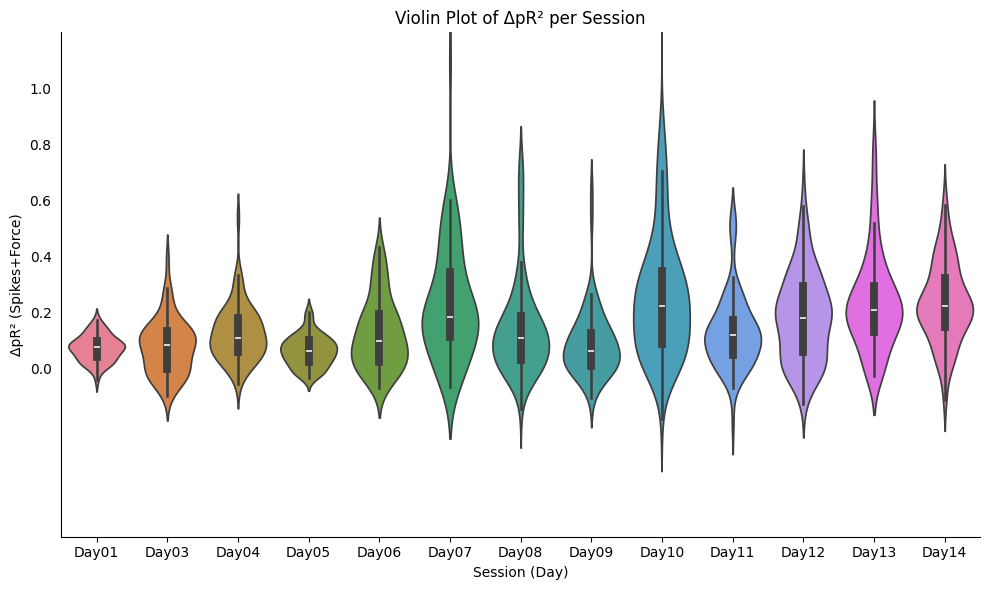

In [104]:
# VIOLIN PLOT SPIKES+FORCE WITH BOOTSTRAPPING

# Collect the ΔpR² values for each session
delta_pR2_values = [session_results[session]["pR2_diff"] for session in session_results]

# Create a figure and axes
plt.figure(figsize=(10, 6))

# Use seaborn to create a violin plot
sns.violinplot(data=delta_pR2_values)

# Customize plot labels and title
plt.xlabel("Session (Day)")
plt.ylabel("ΔpR² (Spikes+Force)")
plt.title("Violin Plot of ΔpR² per Session")

# Add x-ticks (session labels)
plt.xticks(ticks=range(len(session_results)), labels=list(session_results.keys()))

# Set y-axis limits and ticks
plt.ylim(-0.6, 1.2)
plt.yticks(np.arange(0, 1.2, 0.2))  # Set ticks to 0, 0.2, 0.4, ..., 1

# Remove ticks next to the numbers on the y-axis
plt.tick_params(axis='y', which='both', left=False, right=False)

# Remove the top and right spines
sns.despine()

# Adjust layout for better spacing
plt.tight_layout()

# Save the plot as a PDF
plt.savefig('/Users/nmt121/Desktop/GLMS6CV.pdf', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


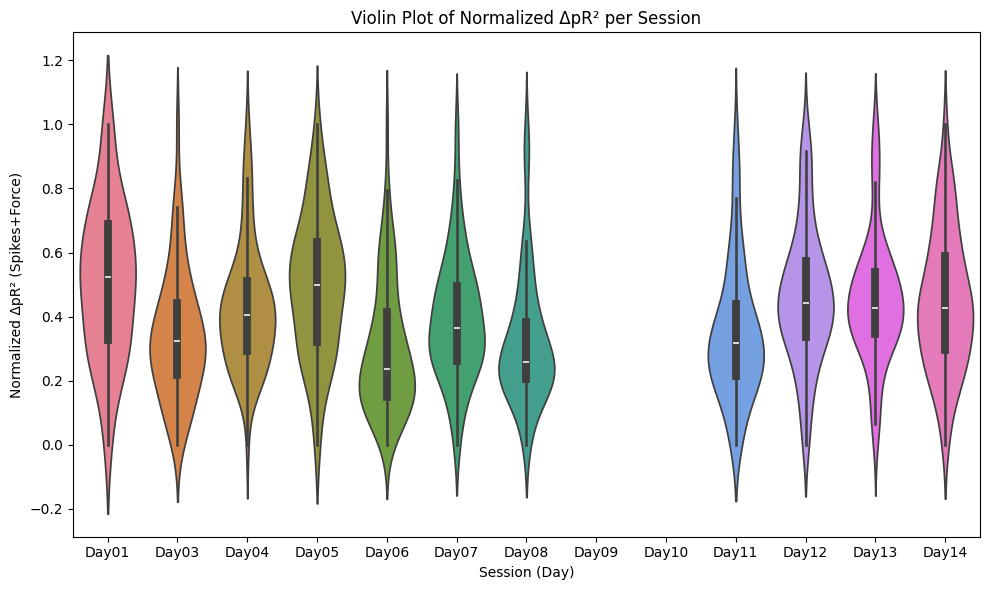

In [ ]:
# SAME PLOT AS BEFORE BUT NORMALIZED WITH FORCE DATA

# Collect the ΔpR² values for each session, normalized by the mean of force-only values
delta_pR2_values = [
    session_results[session]["pR2_diff"] / np.mean(session_other[session]["pR2_force_only"]) 
    for session in session_results
]

# Normalize the values per session between 0 and 1
normalized_delta_pR2_values_per_session = []

session_labels = list(session_results.keys())  # Convert keys to list for indexing

for session in session_labels:
    session_values = delta_pR2_values[session_labels.index(session)]
    
    # Get the min and max for the session
    session_min = np.min(session_values)
    session_max = np.max(session_values)
    
    # Normalize the session values between 0 and 1
    normalized_session_values = (session_values - session_min) / (session_max - session_min)
    
    normalized_delta_pR2_values_per_session.append(normalized_session_values)

# Create a figure and axes
plt.figure(figsize=(10, 6))

# Use seaborn to create a violin plot with the normalized values per session
sns.violinplot(data=normalized_delta_pR2_values_per_session)

# Customize plot labels and title
plt.xlabel("Session (Day)")
plt.ylabel("Normalized ΔpR² (Spikes+Force)")
plt.title("Violin Plot of Normalized ΔpR² per Session")

# Add x-ticks (session labels)
plt.xticks(ticks=range(len(session_labels)), labels=session_labels)

plt.tight_layout()

# plt.savefig('/Users/nmt121/Desktop/GLMS1.pdf', dpi=300, bbox_inches='tight')

plt.show()


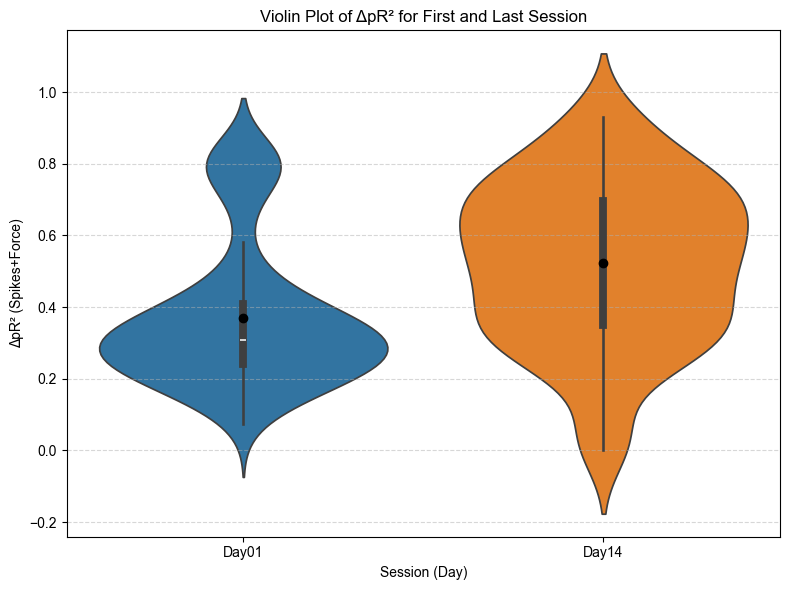

In [26]:
# --- Create Violin Plot for First and Last Session ---

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get session keys and select first and last
session_keys = list(session_results.keys())
selected_keys = [session_keys[0], session_keys[-1]]

# Extract ΔpR² values for the selected sessions
selected_values = [session_results[k]["pR2_diff"] for k in selected_keys]

# Create a figure and axes
plt.figure(figsize=(8, 6))

# Use seaborn to create a violin plot
sns.violinplot(data=selected_values)

# Overlay means as black dots
for i, values in enumerate(selected_values):
    mean_val = np.nanmean(values)
    plt.plot(i, mean_val, 'o', color='black', markersize=6)

# Customize plot labels and title
plt.xlabel("Session (Day)")
plt.ylabel("ΔpR² (Spikes+Force)")
plt.title("Violin Plot of ΔpR² for First and Last Session")
plt.xticks(ticks=range(len(selected_keys)), labels=selected_keys)

plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/GLM1_firstandlastday.pdf', dpi=300, bbox_inches='tight')
plt.show()


Session Day01 - Cleaned Data Length: 147
Session Day03 - Cleaned Data Length: 110
Session Day04 - Cleaned Data Length: 138
Session Day05 - Cleaned Data Length: 126
Session Day06 - Cleaned Data Length: 84
Session Day07 - Cleaned Data Length: 162
Session Day08 - Cleaned Data Length: 114
Session Day09 - Cleaned Data Length: 138
Session Day10 - Cleaned Data Length: 153
Session Day11 - Cleaned Data Length: 92
Session Day12 - Cleaned Data Length: 147
Session Day13 - Cleaned Data Length: 102
Session Day14 - Cleaned Data Length: 107
Kruskal-Wallis H = 199.688, p = 0.00000
Statistically significant difference between sessions.

--- Pairwise Mann-Whitney U tests ---
Day01 vs Day03: U = 9095.00, p = 0.08688
  → Not significant
Day01 vs Day04: U = 6000.00, p = 0.00000
  → Significant difference
Day01 vs Day05: U = 7447.00, p = 0.00529
  → Significant difference
Day01 vs Day06: U = 4529.00, p = 0.00076
  → Significant difference
Day01 vs Day07: U = 7934.00, p = 0.00000
  → Significant difference
Da

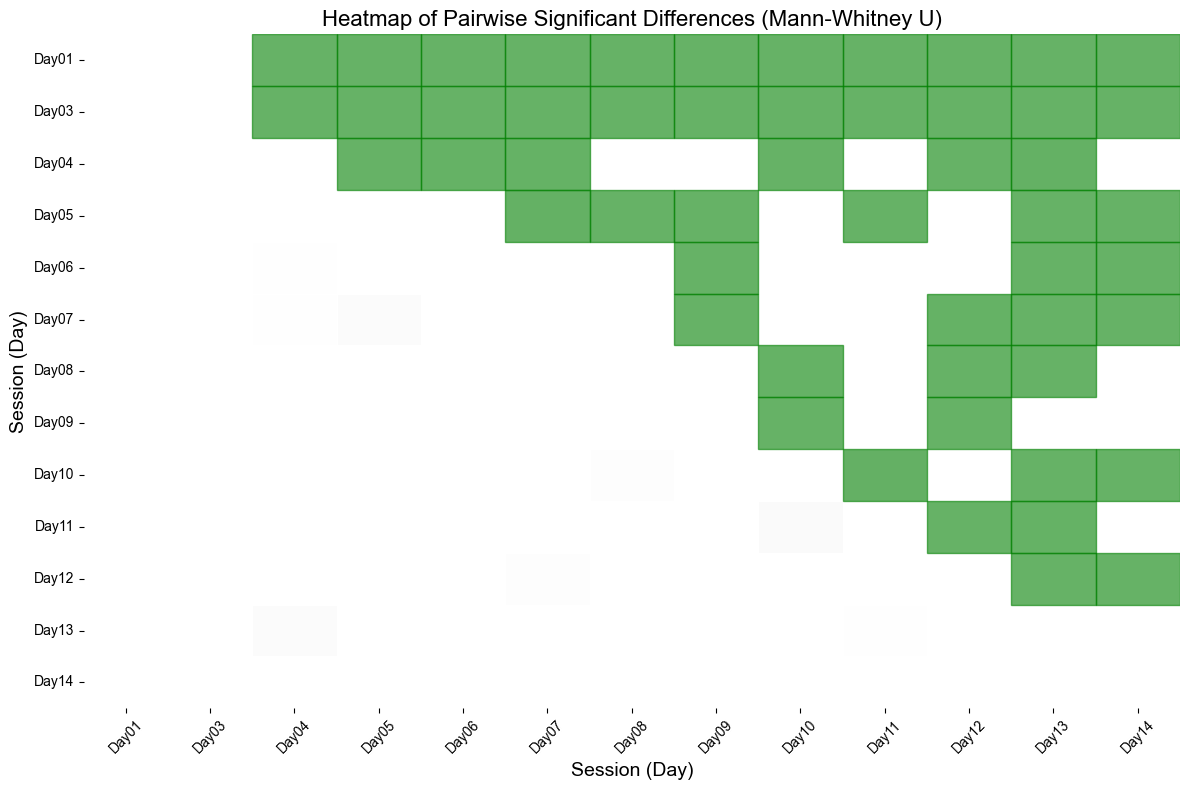

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import itertools
import scipy.stats as stats
import pandas as pd

# --- Define session labels manually (or sorted from session_results) ---
session_labels = sorted(session_results.keys())  # or define your own ordering

# --- Clean session data: remove NaNs from ΔpR² values ---
session_data_clean = [
    session_results[session]["pR2_diff"][~np.isnan(session_results[session]["pR2_diff"])]
    for session in session_labels
]

# --- Check cleaned data (optional) ---
for i, session in enumerate(session_data_clean):
    print(f"Session {session_labels[i]} - Cleaned Data Length: {len(session)}")

# --- Kruskal-Wallis test across all sessions ---
if all(len(session) > 1 for session in session_data_clean):
    h_statistic, p_value = stats.kruskal(*session_data_clean)
    print(f'Kruskal-Wallis H = {h_statistic:.3f}, p = {p_value:.5f}')
    if p_value < 0.05:
        print("Statistically significant difference between sessions.")
    else:
        print("No statistically significant difference between sessions.")
else:
    print("Not enough data to perform Kruskal-Wallis test.")

# --- Pairwise Mann-Whitney U tests (Wilcoxon rank-sum) ---
print("\n--- Pairwise Mann-Whitney U tests ---")
for (i, j) in itertools.combinations(range(len(session_labels)), 2):
    data1 = session_data_clean[i]
    data2 = session_data_clean[j]
    
    stat, p_val = stats.mannwhitneyu(data1, data2, alternative='two-sided')
    print(f"{session_labels[i]} vs {session_labels[j]}: U = {stat:.2f}, p = {p_val:.5f}")
    if p_val < 0.05:
        print("  → Significant difference")
    else:
        print("  → Not significant")

# --- Create p-value matrix for heatmap ---
p_matrix = np.full((len(session_labels), len(session_labels)), np.nan)

for i, session1 in enumerate(session_labels):
    for j, session2 in enumerate(session_labels):
        if i < j:
            data1 = session_data_clean[i]
            data2 = session_data_clean[j]
            stat, p_val = stats.mannwhitneyu(data1, data2, alternative='two-sided')
            p_matrix[i, j] = p_val
            p_matrix[j, i] = p_val  # symmetric

# --- Create a DataFrame for seaborn heatmap ---
p_values_df = pd.DataFrame(p_matrix, index=session_labels, columns=session_labels)

# --- Mask for non-significant comparisons ---
significance_mask = p_matrix < 0.05

# --- Plot heatmap of significance ---
plt.figure(figsize=(12, 8))

# Plot base heatmap in grey for non-significant cells
sns.heatmap(p_values_df, annot=False, cmap='Greys', cbar=False,
            linewidths=0.5, vmin=0, vmax=1, mask=~significance_mask)

# Overlay green rectangles for significant comparisons
ax = plt.gca()
for i in range(len(session_labels)):
    for j in range(i + 1, len(session_labels)):
        if significance_mask[i, j]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, color='green', alpha=0.6))

# Final touches
plt.title("Heatmap of Pairwise Significant Differences (Mann-Whitney U)", fontsize=16)
plt.xlabel("Session (Day)", fontsize=14)
plt.ylabel("Session (Day)", fontsize=14)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/GLM_pairwise_comparison_significance_colored_GLM1.pdf', dpi=300, bbox_inches='tight')
plt.show()


## ONLY FORCE

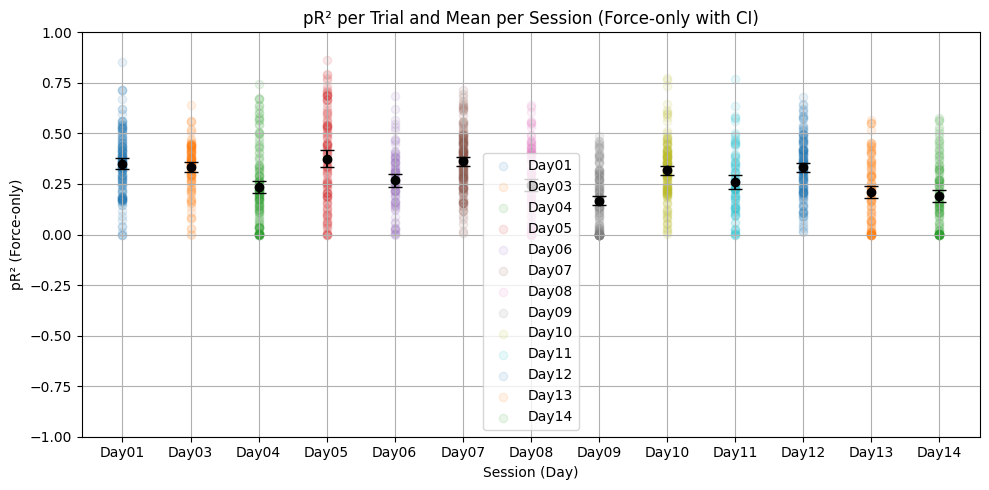

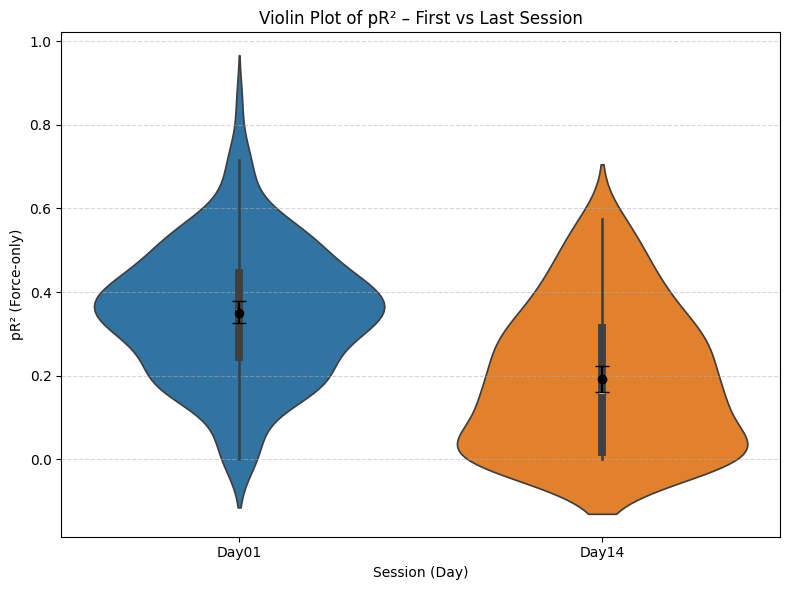

In [9]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S1/'
bin_size_ms = 500
history_bins = 2
session_files = session_files1  # Define externally: {session_name: [file1.pkl, file2.pkl, ...]}
n_bootstrap = 1000

# === FUNCTION TO COMPUTE PSEUDO-R² ===
def compute_pseudo_r2(glm_model, X, Y):
    y_pred = glm_model.predict(X)
    y_pred = np.clip(y_pred, 1e-6, None)
    Y = np.clip(Y, 1e-6, None)

    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan

    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))

    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan

    return 1 - (deviance_model / deviance_null)

# === BOOTSTRAP MEAN AND CI ===
def bootstrap_mean_pr2(data, n_bootstrap=1000):
    data = np.array(data)
    data = data[~np.isnan(data)]
    if len(data) == 0:
        return np.nan, np.nan, np.nan

    boot_means = [np.mean(np.random.choice(data, size=len(data), replace=True)) for _ in range(n_bootstrap)]
    ci_lower, ci_upper = np.percentile(boot_means, [2.5, 97.5])
    return np.mean(boot_means), ci_lower, ci_upper

# === FUNCTION TO LOAD AND BIN SPIKES + FORCE ===
def preprocess_trial(file, bin_size_ms):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()

    data_MU = np.array(data['MU'].tolist())
    min_length = min(force.shape[0], data_MU.shape[1])
    force = force[:min_length]
    data_MU = data_MU[:, :min_length]

    num_bins = min_length // bin_size_ms
    if num_bins == 0:
        print(f"Skipping {file}: Not enough time points for binning.")
        return None, None

    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_ms, bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_ms], np.arange(0, num_bins * bin_size_ms, bin_size_ms)) / bin_size_ms

    return smoothed_spikes[:, :num_bins].T, binned_force[:num_bins]

# === GLM DATA USING ONLY FORCE ===
def prepare_force_only_glm_data(spike_data, force_data, history_bins, target_idx):
    num_timebins, num_neurons = spike_data.shape

    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]
    if target_idx not in active_neurons:
        return None, None

    X_list, Y_list = [], []

    for t in range(history_bins, num_timebins):
        force_t = force_data[t]
        X_list.append([force_t])
        Y_list.append(spike_data[t, target_idx])

    return np.array(X_list), np.array(Y_list)

# === MAIN ANALYSIS LOOP ===
session_results = {}

for session, pkl_files in session_files.items():
    pR2_list = []

    for file in pkl_files:
        spikes, force = preprocess_trial(file, bin_size_ms)
        if spikes is None or force is None:
            continue

        num_neurons = spikes.shape[1]
        for target_idx in range(num_neurons):
            X, Y = prepare_force_only_glm_data(spikes, force, history_bins, target_idx)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            X[np.isnan(X)] = 0
            X_scaled = StandardScaler().fit_transform(X)

            kf = KFold(n_splits=10, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=500), {'alpha': [0.1, 1, 10, 100, 1000]},
                                      cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            best_alpha = poisson_cv.best_params_['alpha']

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
            model.fit(X_scaled, Y)
            pR2 = compute_pseudo_r2(model, X_scaled, Y)
            pR2_list.append(pR2)

    if pR2_list:
        session_results[session] = {
            "pR2_force_only": np.array(pR2_list)
        }

# === BOOTSTRAP SESSION MEANS AND CONFIDENCE INTERVALS ===
session_labels = list(session_results.keys())
session_bootstrap_means = {}

for session in session_labels:
    values = session_results[session]["pR2_force_only"]
    mean, ci_low, ci_high = bootstrap_mean_pr2(values, n_bootstrap=n_bootstrap)
    session_bootstrap_means[session] = {
        "mean": mean,
        "ci_low": ci_low,
        "ci_high": ci_high
    }

# === PLOT WITH ERROR BARS (BOOTSTRAPPED) ===
plt.figure(figsize=(10, 5))
plt.xlabel("Session (Day)")
plt.ylabel("pR² (Force-only)")
plt.ylim([-1, 1])
plt.grid(True)
plt.title("pR² per Trial and Mean per Session (Force-only with CI)")

for i, session in enumerate(session_labels):
    values = session_results[session]["pR2_force_only"]
    stats = session_bootstrap_means[session]
    x_pos = np.full(len(values), i)
    plt.scatter(x_pos, values, alpha=0.1, label=session)
    plt.errorbar(i, stats["mean"],
                 yerr=[[stats["mean"] - stats["ci_low"]], [stats["ci_high"] - stats["mean"]]],
                 fmt='o', color='black', capsize=5, markersize=6)

plt.xticks(ticks=range(len(session_labels)), labels=session_labels)
plt.legend()
plt.tight_layout()
plt.show()

# === VIOLIN PLOT: First vs Last Session ===
first_session = session_labels[0]
last_session = session_labels[-1]
first_values = session_results[first_session]["pR2_force_only"]
last_values = session_results[last_session]["pR2_force_only"]
data_for_violin = [first_values, last_values]
labels = [first_session, last_session]

plt.figure(figsize=(8, 6))
sns.violinplot(data=data_for_violin)

# Overlay bootstrapped means
for i, session in enumerate([first_session, last_session]):
    stats = session_bootstrap_means[session]
    plt.errorbar(i, stats["mean"],
                 yerr=[[stats["mean"] - stats["ci_low"]], [stats["ci_high"] - stats["mean"]]],
                 fmt='o', color='black', capsize=5, markersize=6)

plt.xticks(ticks=[0, 1], labels=labels)
plt.xlabel("Session (Day)")
plt.ylabel("pR² (Force-only)")
plt.title("Violin Plot of pR² – First vs Last Session")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/GLM1_forceonly_first_last_violin.pdf', dpi=300, bbox_inches='tight')
plt.show()


### changing name

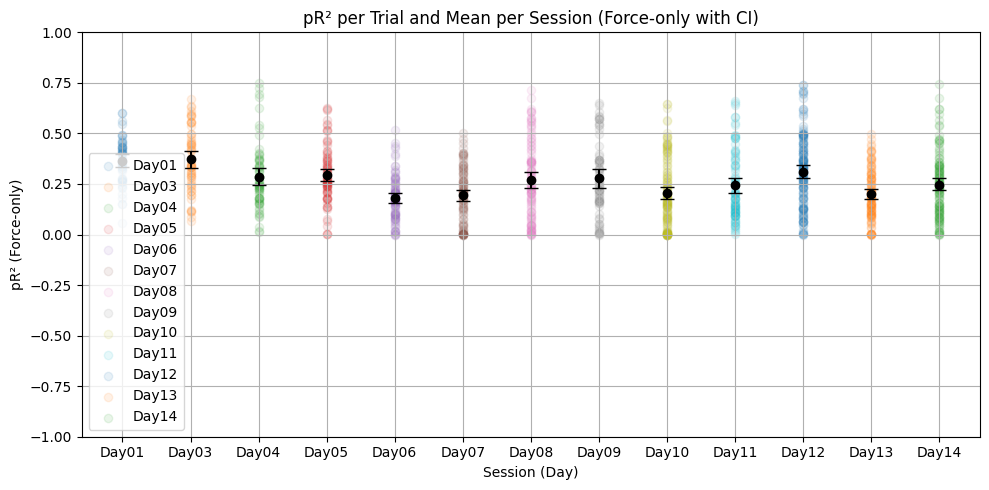

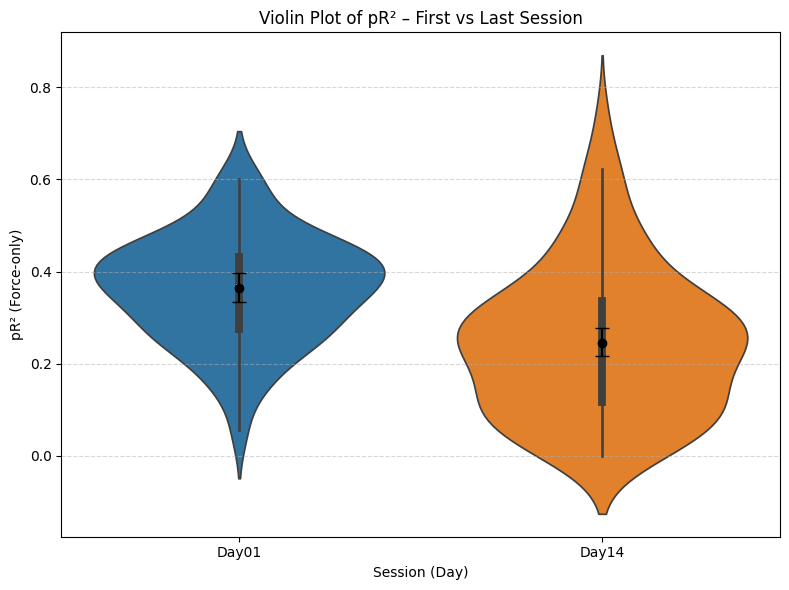

In [52]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S6/'
bin_size_ms = 500
history_bins = 2
session_files = session_files6 # Define externally: {session_name: [file1.pkl, file2.pkl, ...]}
n_bootstrap = 1000

# === FUNCTION TO COMPUTE PSEUDO-R² ===
def compute_pseudo_r2(glm_model, X, Y):
    y_pred = glm_model.predict(X)
    y_pred = np.clip(y_pred, 1e-6, None)
    Y = np.clip(Y, 1e-6, None)

    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan

    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))

    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan

    return 1 - (deviance_model / deviance_null)

# === BOOTSTRAP MEAN AND CI ===
def bootstrap_mean_pr2(data, n_bootstrap=1000):
    data = np.array(data)
    data = data[~np.isnan(data)]
    if len(data) == 0:
        return np.nan, np.nan, np.nan

    boot_means = [np.mean(np.random.choice(data, size=len(data), replace=True)) for _ in range(n_bootstrap)]
    ci_lower, ci_upper = np.percentile(boot_means, [2.5, 97.5])
    return np.mean(boot_means), ci_lower, ci_upper

# === FUNCTION TO LOAD AND BIN SPIKES + FORCE ===
def preprocess_trial(file, bin_size_ms):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()

    data_MU = np.array(data['MU'].tolist())
    min_length = min(force.shape[0], data_MU.shape[1])
    force = force[:min_length]
    data_MU = data_MU[:, :min_length]

    num_bins = min_length // bin_size_ms
    if num_bins == 0:
        print(f"Skipping {file}: Not enough time points for binning.")
        return None, None

    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_ms, bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_ms], np.arange(0, num_bins * bin_size_ms, bin_size_ms)) / bin_size_ms

    return smoothed_spikes[:, :num_bins].T, binned_force[:num_bins]

# === GLM DATA USING ONLY FORCE ===
def prepare_force_only_glm_data(spike_data, force_data, history_bins, target_idx):
    num_timebins, num_neurons = spike_data.shape

    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]
    if target_idx not in active_neurons:
        return None, None

    X_list, Y_list = [], []

    for t in range(history_bins, num_timebins):
        force_t = force_data[t]
        X_list.append([force_t])
        Y_list.append(spike_data[t, target_idx])

    return np.array(X_list), np.array(Y_list)

# === MAIN ANALYSIS LOOP ===
session_other = {}

for session, pkl_files in session_files.items():
    pR2_list = []

    for file in pkl_files:
        spikes, force = preprocess_trial(file, bin_size_ms)
        if spikes is None or force is None:
            continue

        num_neurons = spikes.shape[1]
        for target_idx in range(num_neurons):
            X, Y = prepare_force_only_glm_data(spikes, force, history_bins, target_idx)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            X[np.isnan(X)] = 0
            X_scaled = StandardScaler().fit_transform(X)

            kf = KFold(n_splits=10, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=500), {'alpha': [0.1, 1, 10, 100, 1000]},
                                      cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            best_alpha = poisson_cv.best_params_['alpha']

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
            model.fit(X_scaled, Y)
            pR2 = compute_pseudo_r2(model, X_scaled, Y)
            pR2_list.append(pR2)

    if pR2_list:
        session_other[session] = {
            "pR2_force_only": np.array(pR2_list)
        }

# === BOOTSTRAP SESSION MEANS AND CONFIDENCE INTERVALS ===
session_labels = list(session_other.keys())
session_bootstrap_means = {}

for session in session_labels:
    values = session_other[session]["pR2_force_only"]
    mean, ci_low, ci_high = bootstrap_mean_pr2(values, n_bootstrap=n_bootstrap)
    session_bootstrap_means[session] = {
        "mean": mean,
        "ci_low": ci_low,
        "ci_high": ci_high
    }

# === PLOT WITH ERROR BARS (BOOTSTRAPPED) ===
plt.figure(figsize=(10, 5))
plt.xlabel("Session (Day)")
plt.ylabel("pR² (Force-only)")
plt.ylim([-1, 1])
plt.grid(True)
plt.title("pR² per Trial and Mean per Session (Force-only with CI)")

for i, session in enumerate(session_labels):
    values = session_other[session]["pR2_force_only"]
    stats = session_bootstrap_means[session]
    x_pos = np.full(len(values), i)
    plt.scatter(x_pos, values, alpha=0.1, label=session)
    plt.errorbar(i, stats["mean"],
                 yerr=[[stats["mean"] - stats["ci_low"]], [stats["ci_high"] - stats["mean"]]],
                 fmt='o', color='black', capsize=5, markersize=6)

plt.xticks(ticks=range(len(session_labels)), labels=session_labels)
plt.legend()
plt.tight_layout()
plt.show()

# === VIOLIN PLOT: First vs Last Session ===
first_session = session_labels[0]
last_session = session_labels[-1]
first_values = session_other[first_session]["pR2_force_only"]
last_values = session_other[last_session]["pR2_force_only"]
data_for_violin = [first_values, last_values]
labels = [first_session, last_session]

plt.figure(figsize=(8, 6))
sns.violinplot(data=data_for_violin)

# Overlay bootstrapped means
for i, session in enumerate([first_session, last_session]):
    stats = session_bootstrap_means[session]
    plt.errorbar(i, stats["mean"],
                 yerr=[[stats["mean"] - stats["ci_low"]], [stats["ci_high"] - stats["mean"]]],
                 fmt='o', color='black', capsize=5, markersize=6)

plt.xticks(ticks=[0, 1], labels=labels)
plt.xlabel("Session (Day)")
plt.ylabel("pR² (Force-only)")
plt.title("Violin Plot of pR² – First vs Last Session")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/GLM1_forceonly_first_last_violin.pdf', dpi=300, bbox_inches='tight')
plt.show()


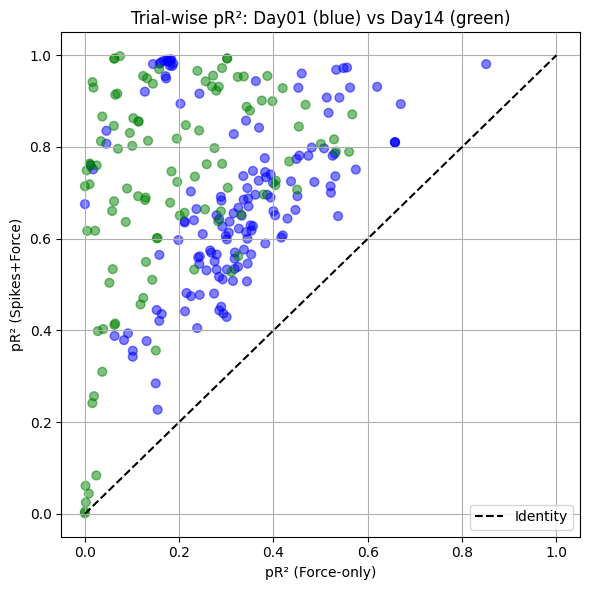

In [3]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S1/'
bin_size_ms = 500
history_bins = 2
n_bootstrap = 1000
session_files = session_files1

# === FUNCTION TO COMPUTE PSEUDO-R² ===
def compute_pseudo_r2(glm_model, X, Y):
    y_pred = glm_model.predict(X)
    y_pred = np.clip(y_pred, 1e-6, None)
    Y = np.clip(Y, 1e-6, None)
    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan
    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))
    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan
    return 1 - (deviance_model / deviance_null)

# === FUNCTION TO BOOTSTRAP pR² MEAN AND CI ===
def bootstrap_mean_pr2(data, n_bootstrap=1000):
    data = np.array(data)
    data = data[~np.isnan(data)]
    if len(data) == 0:
        return np.nan, np.nan, np.nan
    boot_means = [np.mean(np.random.choice(data, size=len(data), replace=True)) for _ in range(n_bootstrap)]
    ci_lower, ci_upper = np.percentile(boot_means, [2.5, 97.5])
    return np.mean(boot_means), ci_lower, ci_upper

# === FUNCTION TO LOAD AND BIN SPIKES + FORCE ===
def preprocess_trial(file, bin_size_ms):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()
    data_MU = np.array(data['MU'].tolist())

    min_length = min(force.shape[0], data_MU.shape[1])
    force = force[:min_length]
    data_MU = data_MU[:, :min_length]
    num_bins = min_length // bin_size_ms
    if num_bins == 0:
        print(f"Skipping {file}: Not enough time points for binning.")
        return None, None

    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_ms, bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_ms], np.arange(0, num_bins * bin_size_ms, bin_size_ms)) / bin_size_ms

    return smoothed_spikes[:, :num_bins].T, binned_force[:num_bins]

# === FUNCTION TO PREPARE GLM INPUT DATA ===
def prepare_glm_data(spike_data, force_data, history_bins, target_idx):
    num_timebins, num_neurons = spike_data.shape
    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]
    if target_idx not in active_neurons:
        return None, None
    X_list, Y_list = [], []
    for t in range(history_bins, num_timebins):
        history = np.hstack([
            spike_data[t - h, np.logical_and(
                np.arange(num_neurons) != target_idx,
                np.isin(np.arange(num_neurons), active_neurons)
            )]
            for h in range(1, history_bins + 1)
        ])
        force_t = force_data[t]
        X_list.append(np.hstack([history, force_t]))
        Y_list.append(spike_data[t, target_idx])
    return np.array(X_list), np.array(Y_list)

# === MAIN ANALYSIS LOOP ===
session_results = {}
session_bootstrap_means = {}

for session, pkl_files in session_files.items():
    pR2_spikes_force = []
    pR2_force_only = []

    for file in pkl_files:
        spikes, force = preprocess_trial(file, bin_size_ms)
        if spikes is None or force is None:
            continue

        num_neurons = spikes.shape[1]
        for target_idx in range(num_neurons):
            X, Y = prepare_glm_data(spikes, force, history_bins, target_idx)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            X[np.isnan(X)] = 0
            X_scaled = StandardScaler().fit_transform(X)

            # Cross-validate best alpha
            kf = KFold(n_splits=10, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=500), {'alpha': [0.1, 1, 10, 100, 1000]},
                                      cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            best_alpha = poisson_cv.best_params_['alpha']

            # Spikes+Force
            model_full = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
            model_full.fit(X_scaled, Y)
            pR2_sf = compute_pseudo_r2(model_full, X_scaled, Y)
            pR2_spikes_force.append(pR2_sf)

            # Force-only
            X_force = X_scaled[:, -1].reshape(-1, 1)
            model_force = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
            model_force.fit(X_force, Y)
            pR2_f = compute_pseudo_r2(model_force, X_force, Y)
            pR2_force_only.append(pR2_f)

    if pR2_spikes_force and pR2_force_only:
        session_results[session] = {
            "pR2_spikes_force": np.array(pR2_spikes_force),
            "pR2_force_only": np.array(pR2_force_only),
            "pR2_diff": np.array(pR2_spikes_force) - np.array(pR2_force_only)
        }

        # Bootstrap means
        mean_sf, ci_low_sf, ci_high_sf = bootstrap_mean_pr2(pR2_spikes_force, n_bootstrap)
        mean_f, ci_low_f, ci_high_f = bootstrap_mean_pr2(pR2_force_only, n_bootstrap)

        session_bootstrap_means[session] = {
            "spikes_force_mean": mean_sf,
            "spikes_force_ci": (ci_low_sf, ci_high_sf),
            "force_only_mean": mean_f,
            "force_only_ci": (ci_low_f, ci_high_f)
        }

# === DEFINE SESSION LABELS ===
session_labels = list(session_results.keys())

# === SCATTER PLOT: pR² (Force-only) vs (Spikes+Force) per trial for first and last session ===
first_session = session_labels[0]
last_session = session_labels[-1]

force_first = session_results[first_session]["pR2_force_only"]
spikes_force_first = session_results[first_session]["pR2_spikes_force"]

force_last = session_results[last_session]["pR2_force_only"]
spikes_force_last = session_results[last_session]["pR2_spikes_force"]

# Combine all trials
x_all = np.concatenate([force_first, force_last])
y_all = np.concatenate([spikes_force_first, spikes_force_last])
colors = ['blue'] * len(force_first) + ['green'] * len(force_last)

# Plot
plt.figure(figsize=(6, 6))
plt.scatter(x_all, y_all, c=colors, alpha=0.5, s=40)
plt.plot([0, 1], [0, 1], 'k--', label='Identity')

plt.xlabel("pR² (Force-only)")
plt.ylabel("pR² (Spikes+Force)")
plt.title(f"Trial-wise pR²: {first_session} (blue) vs {last_session} (green)")
plt.grid(True)
plt.legend()
plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/pR2_scatter_first_last.pdf', dpi=300)
plt.show()


Keys in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_balanced02.jld2: ['spike_array']
Keys in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/force_MN7087_balanced02.jld2: ['force']
Keys in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_balanced04.jld2: ['spike_array']
Keys in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/force_MN7087_balanced04.jld2: ['force']
Keys in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_balanced06.jld2: ['spike_array']
Keys in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/force_MN7087_balanced06.jld2: ['force']
Keys in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_bala

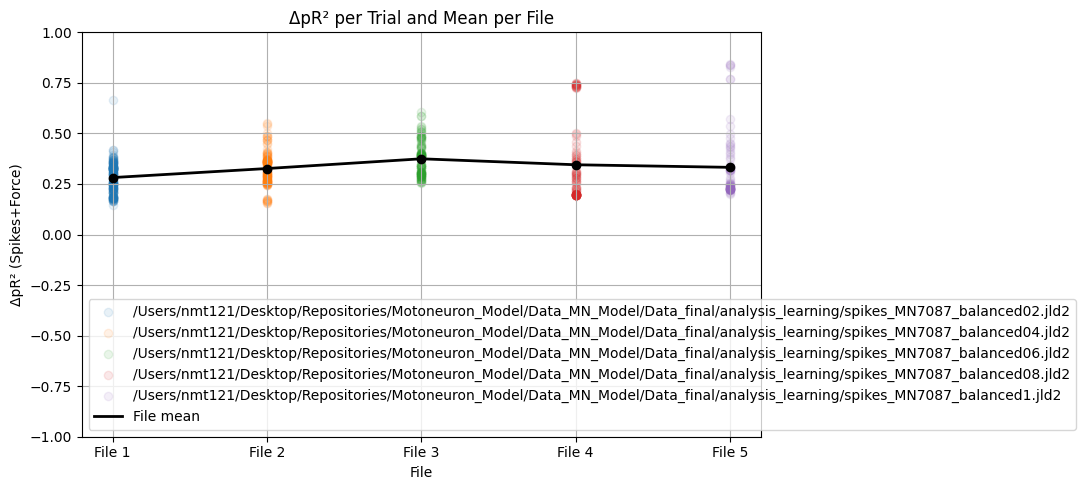

In [76]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor

# === PARAMETERS ===
file_paths = [
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_balanced02.jld2",
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_balanced04.jld2",
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_balanced06.jld2",
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_balanced08.jld2",
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/spikes_MN7087_balanced1.jld2",
]

force_paths = [
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/force_MN7087_balanced02.jld2",
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/force_MN7087_balanced04.jld2",
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/force_MN7087_balanced06.jld2",
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/force_MN7087_balanced08.jld2",
    "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/analysis_learning/force_MN7087_balanced1.jld2",
]

bin_size_ms = 1500
history_bins = 2
n_bootstrap = 1000
fsamp = 20000  # Sampling frequency in Hz (20,000 samples per second)

# === FUNCTION TO COMPUTE PSEUDO-R² ===
def compute_pseudo_r2(glm_model, X, Y):
    y_pred = glm_model.predict(X)
    y_pred = np.clip(y_pred, 1e-6, None)
    Y = np.clip(Y, 1e-6, None)

    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan

    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))

    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan

    return 1 - (deviance_model / deviance_null)

# === FUNCTION TO LOAD SPIKES DATA FROM .JLD2 ===
def load_spikes_from_jld2(file_path):
    with h5py.File(file_path, 'r') as f:
        # Print keys to see what datasets are available in the file
        print(f"Keys in {file_path}: {list(f.keys())}")
        
        # Assuming the spikes data is stored directly as a 2D array (samples x neurons)
        spikes_data = np.array(f[list(f.keys())[0]])  # Accessing the first dataset (adjust if needed)
        
        # Transpose to get neurons x time
        spikes_data = spikes_data.T  # Transpose to match (neurons, time)
        
    return spikes_data

# === FUNCTION TO LOAD FORCE DATA FROM .JLD2 ===
def load_force_from_jld2(file_path):
    with h5py.File(file_path, 'r') as f:
        # Print keys to see what datasets are available in the file
        print(f"Keys in {file_path}: {list(f.keys())}")
        
        # Assuming the force data is stored directly as a 1D array (samples)
        force_data = np.array(f[list(f.keys())[0]])  # Accessing the first dataset (adjust if needed)
        
    return force_data

# === FUNCTION TO PREPROCESS TRIAL ===
def preprocess_trial(spikes_file, force_file, bin_size_ms, fsamp):
    # Load spikes data
    spikes_data = load_spikes_from_jld2(spikes_file)
    
    # Load corresponding force data
    force_data = load_force_from_jld2(force_file)

    # Ensure matching lengths between force and spikes data
    min_length = min(force_data.shape[0], spikes_data.shape[1])
    force_data = force_data[:min_length]
    spikes_data = spikes_data[:, :min_length]

    # Convert bin size from milliseconds to samples
    bin_size_samples = int(bin_size_ms * fsamp / 1000)

    num_bins = min_length // bin_size_samples
    if num_bins == 0:
        print(f"Skipping {spikes_file}: Not enough time points for binning.")
        return None, None

    binned_spikes = np.add.reduceat(spikes_data, np.arange(0, num_bins * bin_size_samples, bin_size_samples), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)

    binned_force = np.add.reduceat(force_data[:num_bins * bin_size_samples], np.arange(0, num_bins * bin_size_samples, bin_size_samples)) / bin_size_samples

    return smoothed_spikes[:, :num_bins].T, binned_force[:num_bins]

# === FUNCTION TO PREPARE GLM DATA ===
def prepare_glm_data(spike_data, force_data, history_bins, target_idx):
    num_timebins, num_neurons = spike_data.shape
    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]

    if target_idx not in active_neurons:
        return None, None

    X_list, Y_list = [], []

    for t in range(history_bins, num_timebins):
        history = np.hstack([
            spike_data[t - h, np.logical_and(
                np.arange(num_neurons) != target_idx,
                np.isin(np.arange(num_neurons), active_neurons)
            )]
            for h in range(1, history_bins + 1)
        ])
        force_t = force_data[t]
        X_list.append(np.hstack([history, force_t]))
        Y_list.append(spike_data[t, target_idx])

    return np.array(X_list), np.array(Y_list)


import numpy as np

# === FUNCTION TO PERFORM BOOTSTRAP ANALYSIS ===
def bootstrap_pr2_analysis_per_session(session_pR2_spikes_force, session_pR2_force_only, n_bootstrap=1000):
    bootstrap_results = {}
    session_bootstrap_means = {}

    # Iterate through each session's data
    for session in session_pR2_spikes_force.keys():
        # Compute the difference between spikes+force and force-only pseudo R² values
        pR2_diff = np.array(session_pR2_spikes_force[session]) - np.array(session_pR2_force_only[session])
        
        # Only keep the trials where pR2_spikes_force > pR2_force_only (i.e., significant trials)
        significant_trials = pR2_diff > 0
        pR2_diff_significant = pR2_diff[significant_trials]

        # If no significant trials, store an error message
        if len(pR2_diff_significant) == 0:
            bootstrap_results[session] = {"Error": "No significant trials found."}
            continue

        # List to store the mean of resampled data
        bootstrap_means = []

        # Perform bootstrap sampling
        for _ in range(n_bootstrap):
            # Resample with replacement from the significant trials
            resampled_trials = np.random.choice(pR2_diff_significant, size=len(pR2_diff_significant), replace=True)
            bootstrap_means.append(np.mean(resampled_trials))

        # Calculate the 95% confidence intervals
        ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

        # Store the mean of the bootstrap samples
        session_bootstrap_means[session] = np.mean(bootstrap_means)

        # Store the results for the session
        bootstrap_results[session] = {
            "Mean difference": np.mean(pR2_diff_significant),
            "95% CI lower bound": ci_lower,
            "95% CI upper bound": ci_upper,
            "Number of significant trials": len(pR2_diff_significant)
        }

    return bootstrap_results, session_bootstrap_means



# === MAIN ANALYSIS LOOP ===
file_results = {}
bootstrap_results = {}
file_pR2_spikes_force = {}
file_pR2_force_only = {}

# Process each file
for spikes_file, force_file in zip(file_paths, force_paths):
    spikes_force_list = []
    force_only_list = []

    spikes, force = preprocess_trial(spikes_file, force_file, bin_size_ms, fsamp)
    if spikes is None or force is None:
        continue

    num_neurons = spikes.shape[1]
    for target_idx in range(num_neurons):
        X, Y = prepare_glm_data(spikes, force, history_bins, target_idx)
        if X is None or Y is None or np.sum(Y) < 20:
            continue

        X[np.isnan(X)] = 0
        X_scaled = StandardScaler().fit_transform(X)

        kf = KFold(n_splits=10, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(PoissonRegressor(max_iter=500), {'alpha': [0.1, 1, 10, 100, 1000]},
                                  cv=kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X_scaled, Y)
        best_alpha = poisson_cv.best_params_['alpha']

        model_full = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
        model_full.fit(X_scaled, Y)
        pR2_spikes_force = compute_pseudo_r2(model_full, X_scaled, Y)

        model_force = PoissonRegressor(alpha=best_alpha, max_iter=1000, solver='newton-cholesky')
        model_force.fit(X_scaled[:, -1].reshape(-1, 1), Y)
        pR2_force_only = compute_pseudo_r2(model_force, X_scaled[:, -1].reshape(-1, 1), Y)

        # **FILTERING OUT TRIALS WHERE pR2_spikes_force <= pR2_force_only**
        if pR2_spikes_force > pR2_force_only:
            spikes_force_list.append(pR2_spikes_force)
            force_only_list.append(pR2_force_only)

    if spikes_force_list and force_only_list:
        file_pR2_spikes_force[spikes_file] = spikes_force_list
        file_pR2_force_only[spikes_file] = force_only_list

# Run bootstrap analysis
bootstrap_results, file_bootstrap_means = bootstrap_pr2_analysis_per_file(
    file_pR2_spikes_force, file_pR2_force_only, n_bootstrap=n_bootstrap
)

# Store the full results for each file
for spikes_file in file_pR2_spikes_force.keys():
    file_results[spikes_file] = {
        "pR2_spikes_force": np.array(file_pR2_spikes_force[spikes_file]),
        "pR2_force_only": np.array(file_pR2_force_only[spikes_file]),
        "pR2_diff": np.array(file_pR2_spikes_force[spikes_file]) - np.array(file_pR2_force_only[spikes_file])
    }

# === PLOTTING RESULTS ===
plt.figure(figsize=(10, 5))
plt.xlabel("File")
plt.ylabel("ΔpR² (Spikes+Force)")
plt.ylim([-1, 1])
plt.grid(True)
plt.title("ΔpR² per Trial and Mean per File")

file_labels = list(file_results.keys())
file_means = []
file_x_positions = []

for i, spikes_file in enumerate(file_labels):
    trial_diffs = file_results[spikes_file]["pR2_diff"]
    x_pos = np.full(len(trial_diffs), i)
    plt.scatter(x_pos, trial_diffs, alpha=0.1, label=spikes_file)
    file_mean = np.nanmean(trial_diffs)
    file_means.append(file_mean)
    file_x_positions.append(i)
    plt.plot(i, file_mean, 'o', color='black', markersize=6)

plt.plot(file_x_positions, file_means, linestyle='-', color='black', linewidth=2, label='File mean')
plt.xticks(ticks=range(len(file_labels)), labels=[f"File {i+1}" for i in range(len(file_labels))])
plt.legend()
plt.tight_layout()
plt.show()


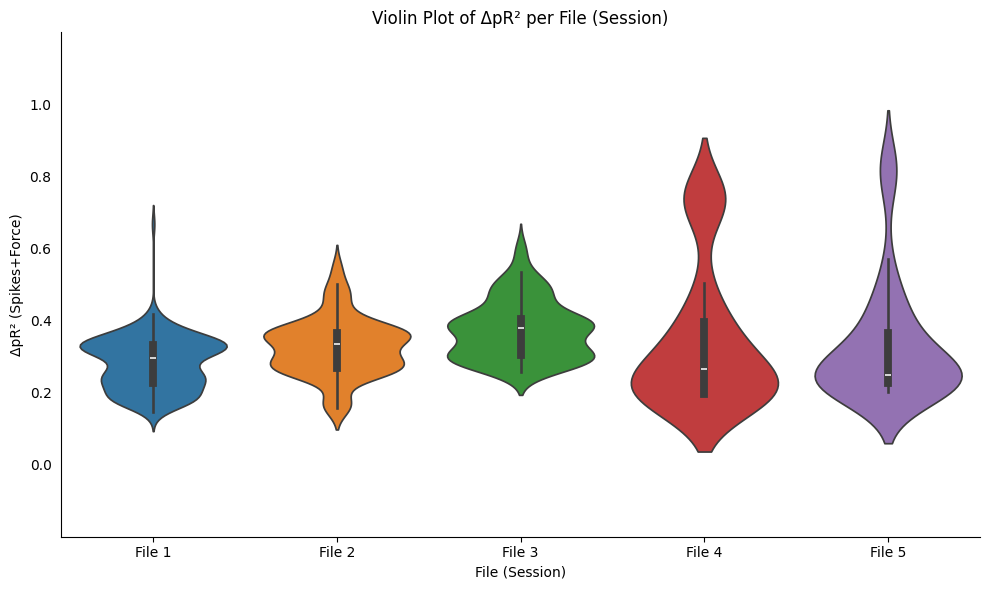

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Assuming you have the `file_results` dictionary populated (as in your previous code)

# Collect the ΔpR² values for each file
delta_pR2_values = [file_results[file]["pR2_diff"] for file in file_results]

# Create a figure and axes
plt.figure(figsize=(10, 6))

# Use seaborn to create a violin plot
sns.violinplot(data=delta_pR2_values)

# Customize plot labels and title
plt.xlabel("File (Session)")
plt.ylabel("ΔpR² (Spikes+Force)")
plt.title("Violin Plot of ΔpR² per File (Session)")

# Add x-ticks (file/session labels)
plt.xticks(ticks=range(len(file_results)), labels=[f"File {i+1}" for i in range(len(file_results))])

# Set y-axis limits and ticks
plt.ylim(-0.2, 1.2)
plt.yticks(np.arange(0, 1.2, 0.2))  # Set ticks to 0, 0.2, 0.4, ..., 1

# Remove ticks next to the numbers on the y-axis
plt.tick_params(axis='y', which='both', left=False, right=False)

# Remove the top and right spines
sns.despine()

# Adjust layout for better spacing
plt.tight_layout()

# Save the plot as a PDF
plt.savefig('/Users/nmt121/Desktop/trial.svg', dpi=300)

# Show the plot
plt.show()


## RASTER PLOTS



In [157]:
folder_path = '/Users/nmt121/Desktop/DATA/S1'
Fsamp = 2048

def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return int(match.group(1)[3:]) if match else None  # Extract numeric part of "DayXX"

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  # Extracts numeric trial number before a non-digit
    return int(match.group(1)) if match else 0  # Default to 0 if no match found


# Sort files by (Day, Trial)
pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.pkl')],key=lambda x: (extract_day(x), extract_trial(x)))

num_files = len(pkl_files)
cols = 3
rows = math.ceil(num_files / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows), sharex=False, sharey=True)
axes = axes.flatten()

for idx, file in enumerate(pkl_files):
    file_path = os.path.join(folder_path, file)

    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_MU = np.array(data['MU'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()

    ax = axes[idx]

    for i in range(data_MU.shape[0]):
        spike_times = np.where(data_MU[i] == 1)[0] / Fsamp

        if i == idx_pair[0]:
            colorline = 'red'
        elif i == idx_pair[1]:
            colorline = 'blue'
        else:
            colorline = 'black'

        ax.vlines(spike_times, i + 0.5, i + 1.5, color=colorline, linewidth=0.5)

    ax.set_title(f'{file}', fontsize=10)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Neurons')

for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/trial.pdf', dpi=300, bbox_inches='tight')
plt.show()




## FORCE

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_34295/1723993181.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


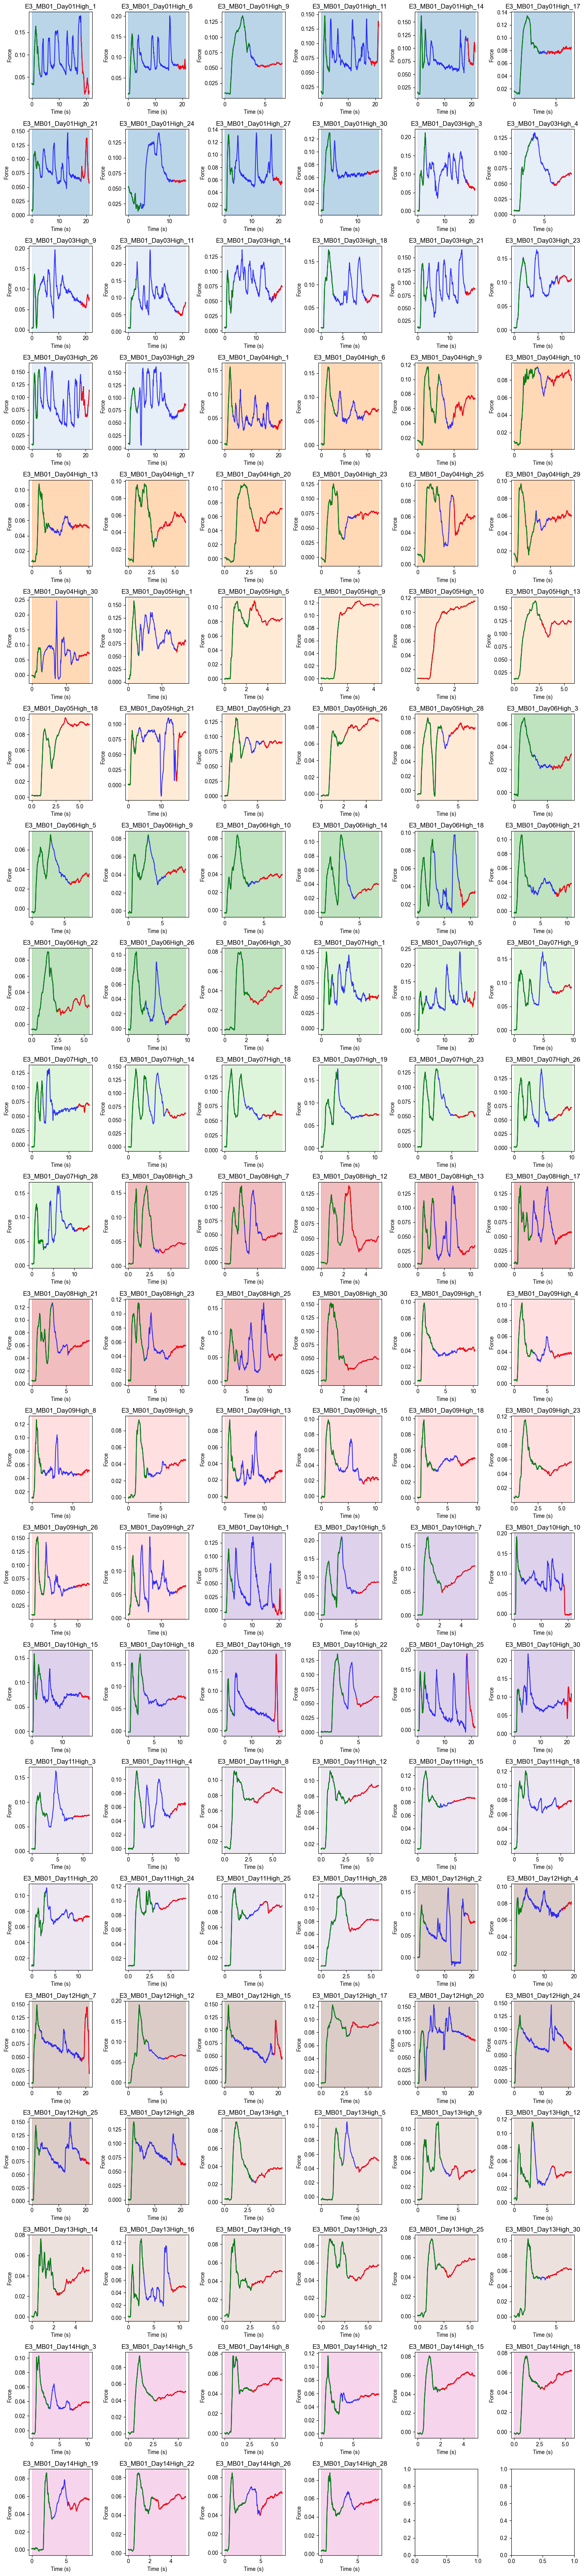

In [155]:
fsamp = 2048  
highlight_samples = int(3 * fsamp)  

directory_path = "/Users/nmt121/Desktop/DATA/S1"

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

# Color mapping for each day
num_days = len(session_days)
if num_days <= 20:
    color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: cm.viridis(i / num_days) for i, day in enumerate(session_days)}  

num_files = len(sorted_pkl_files)
cols = 6  
rows = int(np.ceil(num_files / cols)) 

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten()

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  
    time_axis = np.arange(len(data_FORCE)) / fsamp  

    start_region = np.arange(highlight_samples)  
    end_region = np.arange(len(data_FORCE) - highlight_samples, len(data_FORCE))  

    day_info = extract_day(file_name)  
    day_color = color_map.get(day_info, "white")  

    idx = np.array(data['idx'].tolist()[0])
    data_MU = np.array(data['MU'].tolist())
    data_RATE = np.array(data['DR'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()


    neuron_1 = idx_pair[0]
    neuron_2 = idx_pair[1]

    # Compute Smoothed Firing Rate
    # s1, s2 = conv_spikes(data_MU, neuron_1, neuron_2, fs=data['fsamp'])

    ax = axes[i]
    ax.plot(time_axis, data_FORCE, color="blue", alpha=0.8, label=f"{file_name}")

    ax.axvspan(time_axis[0], time_axis[-1], color=day_color, alpha=0.3, zorder=-10)

    ax.plot(time_axis[start_region], data_FORCE[start_region], color="green", alpha=1)
    ax.plot(time_axis[end_region], data_FORCE[end_region], color="red", alpha=1)

    # ax.plot(s1,s2, color="green", alpha=1)
        
    ax.set_title(file_name.split('.')[0])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Force")

plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')



/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_34295/405001549.py:49: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


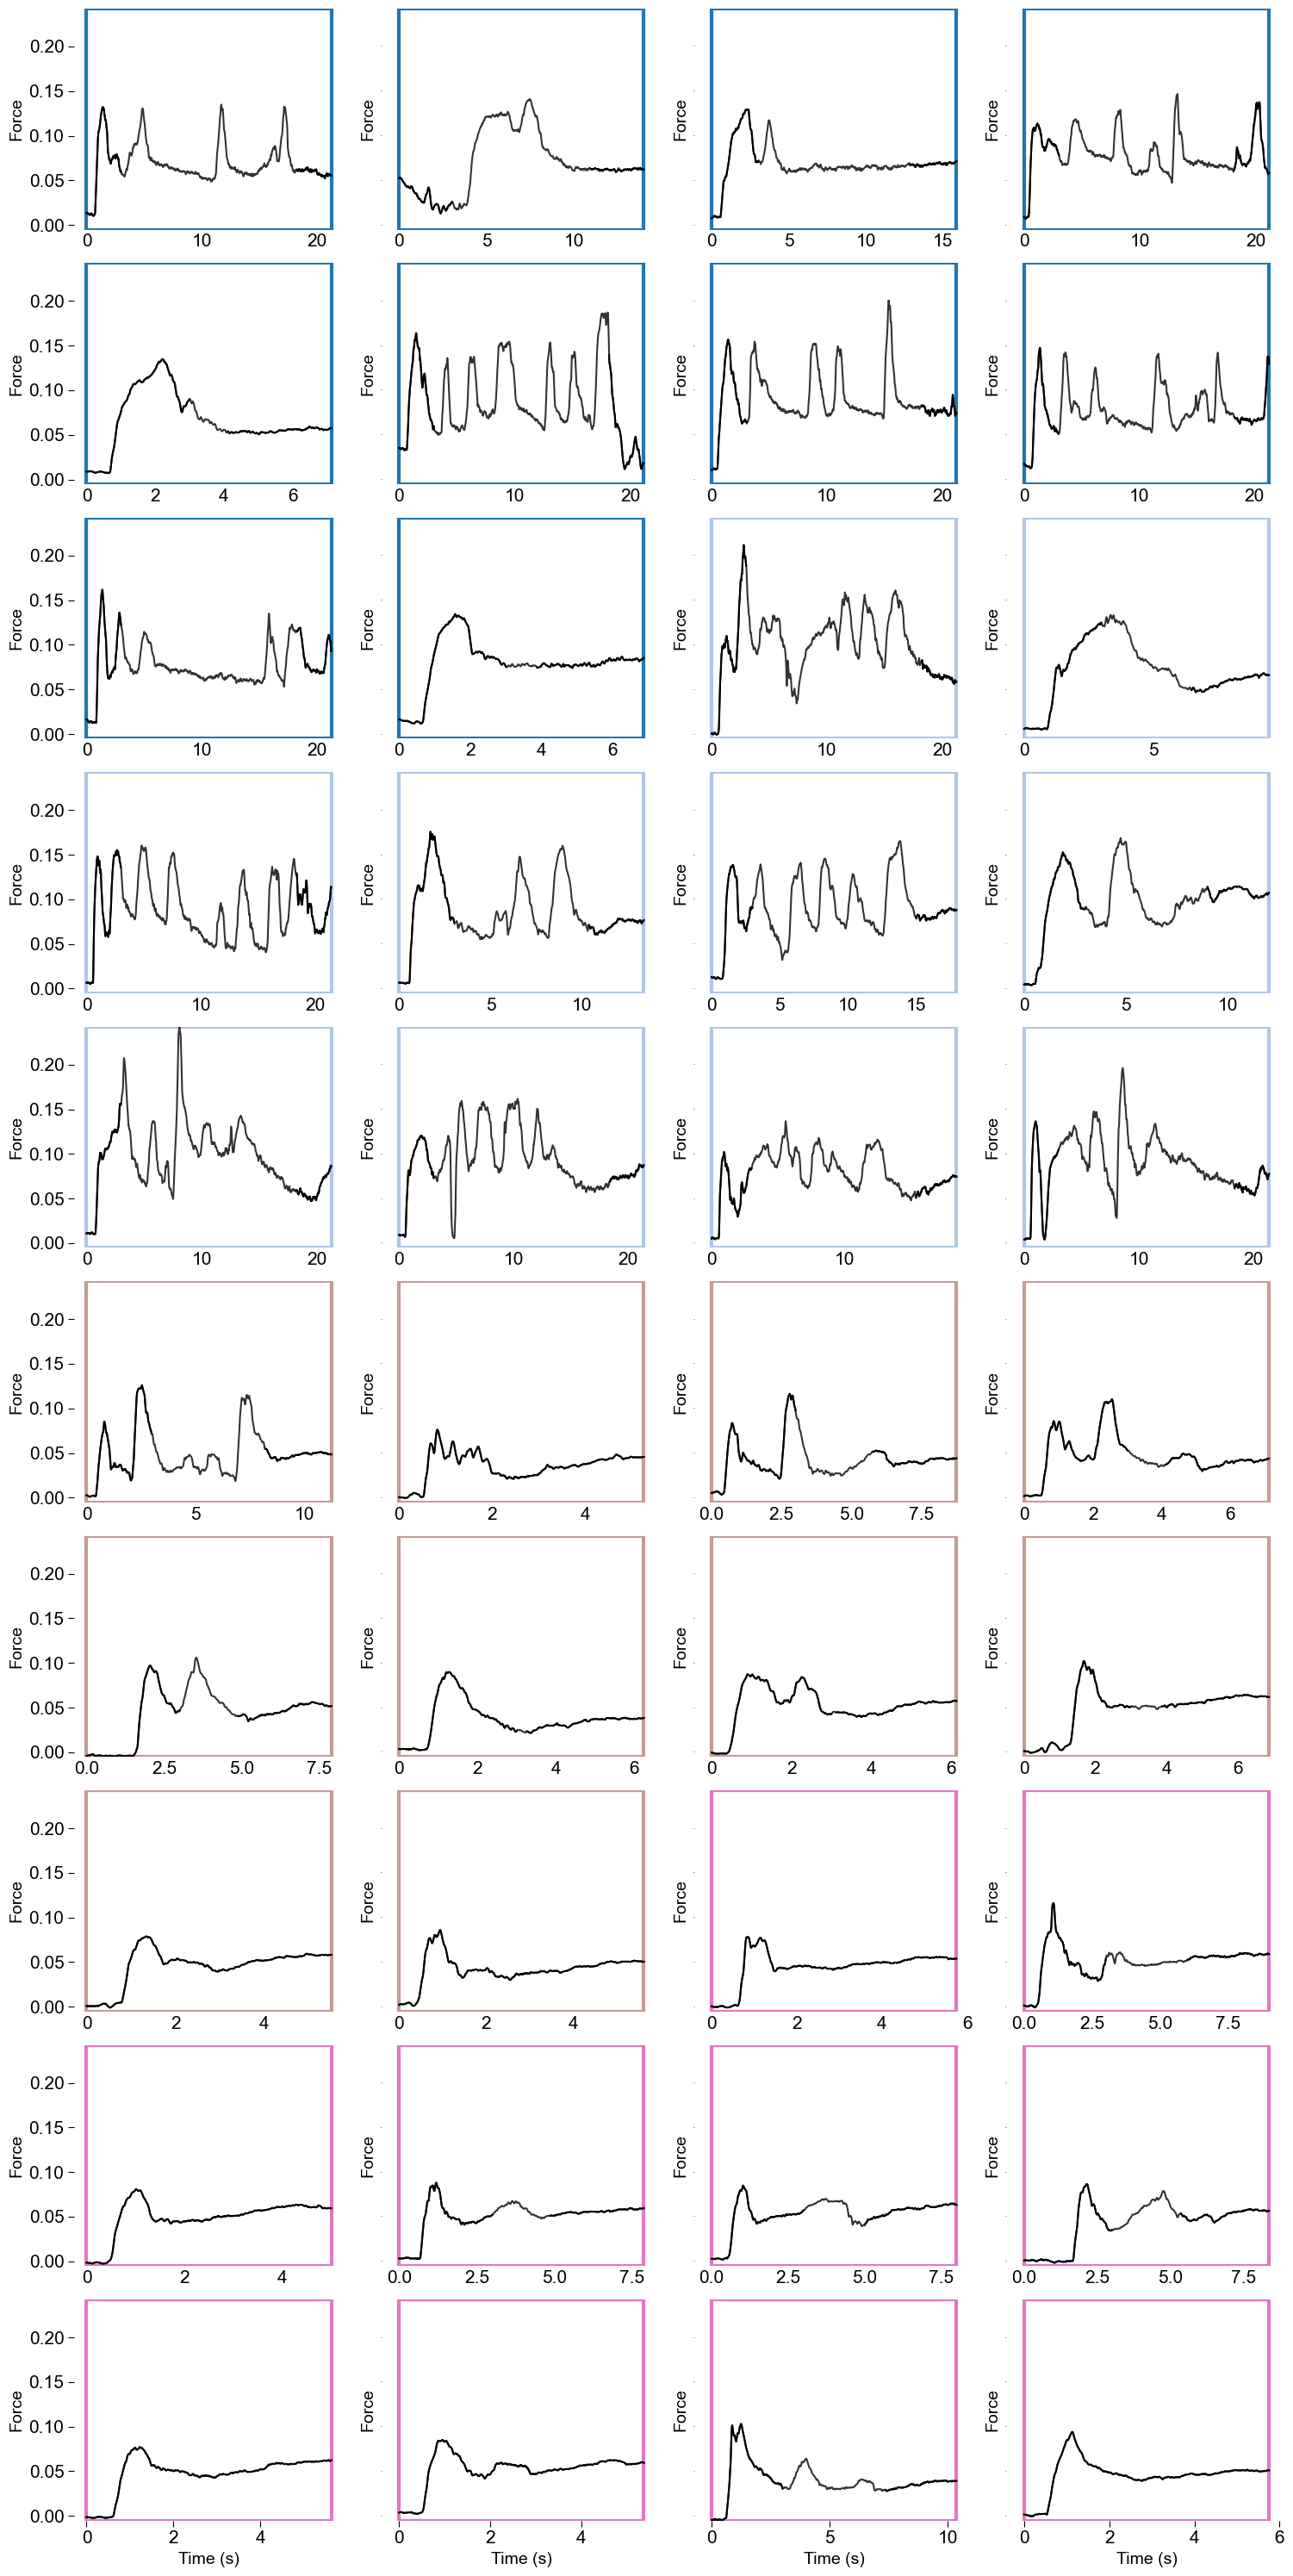

In [152]:
import os
import re
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# Constants
fsamp = 2048  
highlight_samples = int(3 * fsamp)  
directory_path = "/Users/nmt121/Desktop/DATA/S1"

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly
session_days = sorted(files_by_day.keys())

# Select only the first 2 and last 2 sessions
selected_sessions = session_days[:2] + session_days[-2:]

# Get all files for the first 2 and last 2 sessions
sorted_pkl_files = []
for day in selected_sessions:
    sorted_pkl_files.extend(files_by_day[day])

# Color mapping for each day
num_days = len(session_days)
if num_days <= 20:
    color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: cm.viridis(i / num_days) for i, day in enumerate(session_days)}  

# Set up the plot grid
num_files = len(sorted_pkl_files)
cols = 4  
rows = int(np.ceil(num_files / cols)) 

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten()

# Initialize variables for uniform y-limits
all_forces = []

# First pass: Collect all Force data to calculate the global y-limits
for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  
    all_forces.extend(data_FORCE)  # Flatten into a single list

# Convert all_force list to a numpy array for global min/max calculation
all_forces = np.array(all_forces)

# Calculate global min and max for y-limits
ymin = np.min(all_forces)
ymax = np.max(all_forces)

# Plot the data
for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  
    time_axis = np.arange(len(data_FORCE)) / fsamp  

    start_region = np.arange(highlight_samples)  
    end_region = np.arange(len(data_FORCE) - highlight_samples, len(data_FORCE))  

    day_info = extract_day(file_name)  
    day_color = color_map.get(day_info, "white")  

    idx = np.array(data['idx'].tolist()[0])
    data_MU = np.array(data['MU'].tolist())
    data_RATE = np.array(data['DR'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()

    neuron_1 = idx_pair[0]
    neuron_2 = idx_pair[1]

    ax = axes[i]
    ax.plot(time_axis, data_FORCE, color="black", alpha=0.8, label=f"{file_name}")

    # Draw the rectangle with a colored border (thicker border)
    ax.add_patch(plt.Rectangle((0, ymin), time_axis[-1], ymax - ymin, color='white', 
                               ec=day_color, lw=3, fill=False, zorder=-30))  # Increased border thickness

    ax.plot(time_axis[start_region], data_FORCE[start_region], color="black", alpha=1)
    ax.plot(time_axis[end_region], data_FORCE[end_region], color="black", alpha=1)

    ax.set_ylabel("Force", fontsize=14)

    # Set uniform y-limits
    ax.set_ylim(ymin, ymax)
    
    # Remove y-axis ticks and x-axis ticks for non-first plots
    ax.tick_params(axis='y', which='both', length=0, labelsize=0)
    ax.tick_params(axis='x', which='both', length=0, labelsize=15)
    
    # Remove the black borders (spines)
    for spine in ax.spines.values():
        spine.set_visible(False)
    
    # Only show y-ticks and y-label on the first plot of each row
    if i % cols == 0:
        ax.set_ylabel("Force", fontsize=14)
        ax.tick_params(axis='y', which='both', length=5, labelsize=15)  # Increase y-tick size

    # Only show x-ticks and x-label on the last row of plots
    if i >= (rows - 1) * cols:
        ax.set_xlabel("Time (s)", fontsize=14)
        ax.tick_params(axis='x', which='both', length=5, labelsize=15)  # Increase x-tick size

# Adjust layout and show the plot
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/S1force.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
from scipy.stats import kruskal, mannwhitneyu

# Prepare data for Kruskal-Wallis test
sessions = list(session_results.keys())  # List of session names
delta_pR2_values_per_session = [session_results[session] for session in sessions]

# Kruskal-Wallis Test to compare ΔpR² across sessions
stat, p_value = kruskal(*delta_pR2_values_per_session)
print(f"Kruskal-Wallis test statistic: {stat}, p-value: {p_value}")

# If Kruskal-Wallis test is significant, perform post-hoc pairwise comparisons
if p_value < 0.05:
    print("\nPerforming pairwise Mann-Whitney U test between sessions:")
    for i in range(len(sessions)):
        for j in range(i + 1, len(sessions)):
            stat, p_value = mannwhitneyu(delta_pR2_values_per_session[i], delta_pR2_values_per_session[j])
            print(f"Session {sessions[i]} vs Session {sessions[j]}: p-value = {p_value}")
else:
    print("\nNo significant differences between sessions based on Kruskal-Wallis test.")


Kruskal-Wallis test statistic: nan, p-value: nan

No significant differences between sessions based on Kruskal-Wallis test.


## PEAKS PER SUBJECT

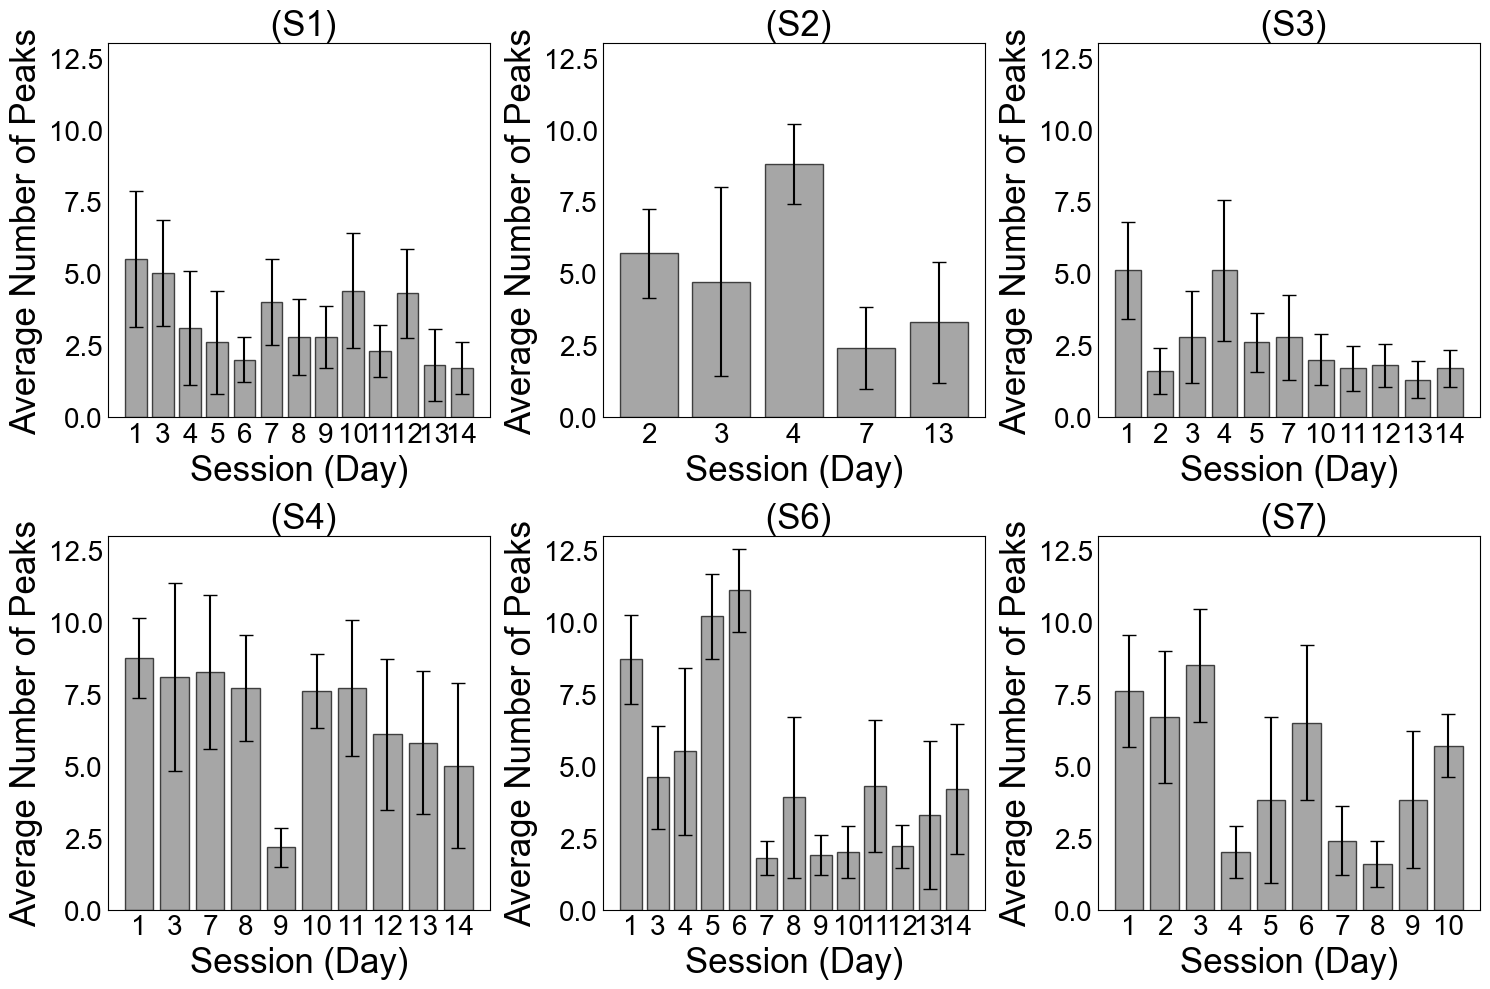

In [52]:
import os
import re
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import find_peaks
from matplotlib.ticker import MaxNLocator

# Constants
fsamp = 2048  
highlight_samples = int(3 * fsamp)  

directory_paths = {
    "S1": "/Users/nmt121/Desktop/DATA/S1",
    "S2": "/Users/nmt121/Desktop/DATA/S2",
    "S3": "/Users/nmt121/Desktop/DATA/S3",
    "S4": "/Users/nmt121/Desktop/DATA/S4",
    "S6": "/Users/nmt121/Desktop/DATA/S6",
    "S7": "/Users/nmt121/Desktop/DATA/S7"
}

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Define Low-pass filter (Butterworth)
def lowpass_filter(data, cutoff=0.5, fs=fsamp, order=4):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    return signal.filtfilt(b, a, data)

# Initialize the figure with subplots, increase the width
fig, axes = plt.subplots(2, 3, figsize=(15, 10))  # Adjusted width from 12 to 15
axes = axes.flatten()  # Flatten to easily iterate over axes

# Loop through each folder (S1, S2, S3, S4) and generate the plots
for idx, (folder_name, directory_path) in enumerate(directory_paths.items()):
    # Get all files and group by day
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    # Create a dictionary grouping files by their respective days
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day:
            if day not in files_by_day:
                files_by_day[day] = []
            files_by_day[day].append(file)

    # Sort the days correctly
    session_days = sorted(files_by_day.keys())

    # Sort files within each day numerically
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    # Flatten the sorted list to get the final ordered file list
    sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

    # Initialize a dictionary to store peak counts by day
    peak_counts_by_day = {day: [] for day in session_days}

    for i, file_name in enumerate(sorted_pkl_files):
        file_path = os.path.join(directory_path, file_name)
        
        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_FORCE = np.array(data['Force'].tolist())[0]  
        time_axis = np.arange(len(data_FORCE)) / fsamp  

        # Apply Low-pass filter (0.5 Hz)
        filtered_force = lowpass_filter(data_FORCE)

        # Find peaks in the filtered force data
        peaks, _ = find_peaks(filtered_force)

        # Count the number of peaks in the trial
        num_peaks = len(peaks)

        day = extract_day(file_name)
        if day:
            peak_counts_by_day[day].append(num_peaks)

    avg_peaks_per_day = [np.mean(peak_counts_by_day[day]) for day in session_days]
    std_peaks_per_day = [np.std(peak_counts_by_day[day]) for day in session_days]

    # Plot with black borders and gray bars
    bars = axes[idx].bar(session_days, avg_peaks_per_day, yerr=std_peaks_per_day, color='gray', edgecolor='black', alpha=0.7, capsize=5)

    # Adjust axis labels
    axes[idx].set_xlabel("Session (Day)", fontsize=25)
    axes[idx].set_ylabel("Average Number of Peaks", fontsize=25)
    axes[idx].set_title(f" ({folder_name})", fontsize=25)
    axes[idx].set_ylim([0, 13])

    # Format x-axis ticks to show only integer values (no decimals)
    axes[idx].set_xticks(np.arange(len(session_days)))  # Ensures ticks are aligned with session days
    axes[idx].set_xticklabels([str(int(day[3:])) for day in session_days])  # Remove leading 0 from "DayXX"

    # Adjust the tick label size
    axes[idx].tick_params(axis='x', labelsize=20)
    axes[idx].tick_params(axis='y', labelsize=20)

    # Remove small ticks from the x and y axis
    axes[idx].tick_params(axis='x', which='both', length=0)
    axes[idx].tick_params(axis='y', which='both', length=0)

# Adjust layout for better spacing
plt.tight_layout()

# Save the figure as a PDF on the desktop
plt.savefig("/Users/nmt121/Desktop/peaks2.pdf", dpi=300, bbox_inches='tight')

# Display the plot
plt.show()


## trial duration

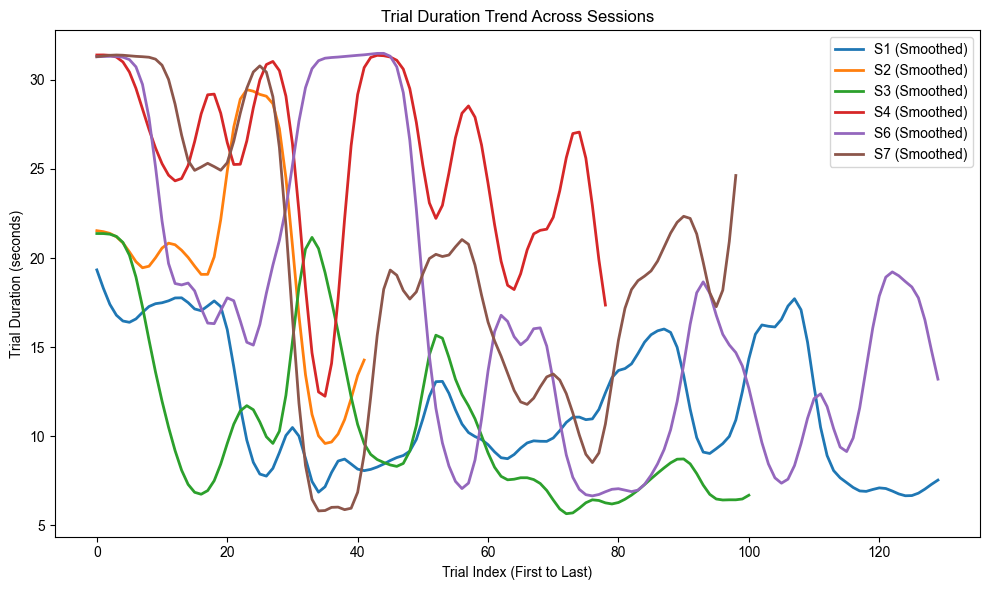

In [103]:
fsamp = 2048  


# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Store trial durations for each session
trial_durations_dict = {}

for session, directory_path in directory_paths.items():
    if not os.path.exists(directory_path):
        print(f"⚠️ Warning: Directory {directory_path} does not exist. Skipping.")
        continue

    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    # Group files by day
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day:
            if day not in files_by_day:
                files_by_day[day] = []
            files_by_day[day].append(file)

    # Sort days correctly
    session_days = sorted(files_by_day.keys())

    # Sort files within each day numerically
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    # Flatten sorted list
    sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

    # Store trial durations
    trial_durations = []

    for file_name in sorted_pkl_files:
        file_path = os.path.join(directory_path, file_name)
        
        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_FORCE = np.array(data['Force'].tolist())[0]  
        trial_duration = len(data_FORCE) / fsamp  # Compute trial duration in seconds
        trial_durations.append(trial_duration)

    trial_durations_dict[session] = trial_durations

# Ensure there is data before proceeding
if not trial_durations_dict:
    print("⚠️ No valid trial data found. Check your directory paths and file structure.")
else:
    # Align data with NaN padding
    max_trials = max(len(trials) for trials in trial_durations_dict.values())
    aligned_data = {session: np.pad(trials, (0, max_trials - len(trials)), constant_values=np.nan)
                    for session, trials in trial_durations_dict.items()}

    # Convert to DataFrame for plotting
    df = pd.DataFrame(aligned_data)

    # Apply Gaussian smoothing
    smoothed_data = df.apply(lambda x: gaussian_filter1d(x, sigma=2, mode='nearest'), axis=0)

    # Plot results
    plt.figure(figsize=(10, 6))

    for session in df.columns:
        # plt.scatter(range(len(df[session])), df[session], alpha=0.6, label=f"{session} (Raw)")
        plt.plot(range(len(smoothed_data[session])), smoothed_data[session], linewidth=2, label=f"{session} (Smoothed)")

    plt.xlabel("Trial Index (First to Last)")
    plt.ylabel("Trial Duration (seconds)")
    plt.title("Trial Duration Trend Across Sessions")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/trialdurfour.pdf', dpi=300, bbox_inches='tight')

    # Show the plot
    plt.show()


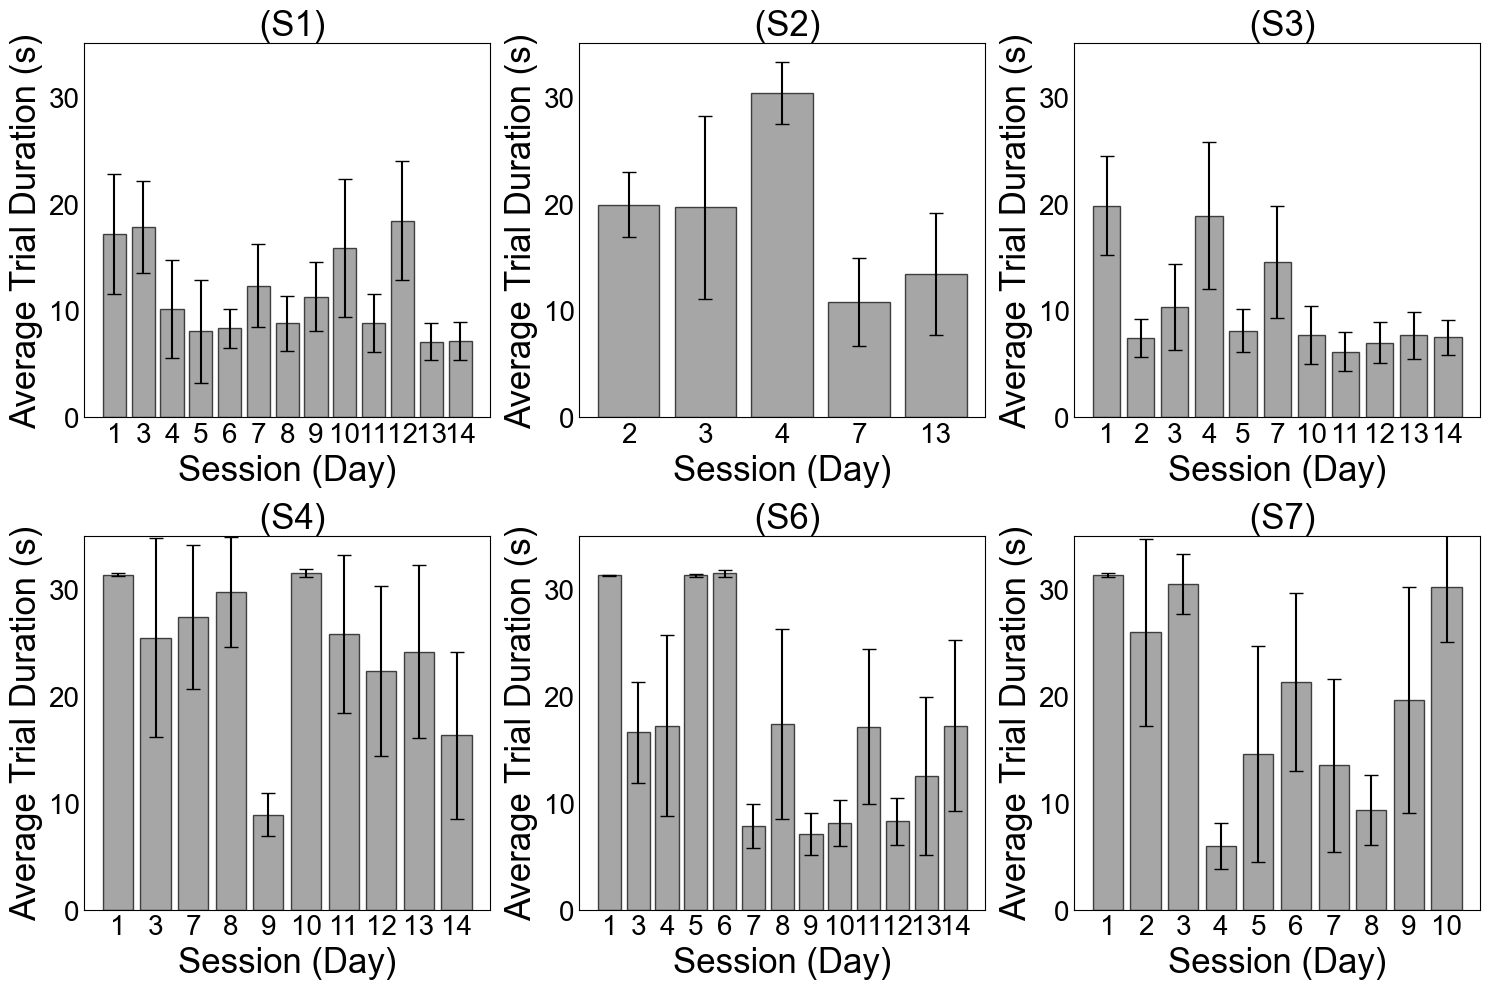

In [56]:
# Initialize the figure with subplots
fig, axes = plt.subplots(2, 3, figsize=(15, 10))  # Adjusted width from 12 to 15
axes = axes.flatten()  # Flatten to easily iterate over axes

# Loop through each folder (S1, S2, S3, S4) and generate the plots
for idx, (folder_name, directory_path) in enumerate(directory_paths.items()):
    # Get all files and group by day
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    # Create a dictionary grouping files by their respective days
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day:
            if day not in files_by_day:
                files_by_day[day] = []
            files_by_day[day].append(file)

    # Sort the days correctly
    session_days = sorted(files_by_day.keys())

    # Sort files within each day numerically
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    # Flatten the sorted list to get the final ordered file list
    sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

    # Initialize a dictionary to store trial durations by day
    trial_durations_by_day = {day: [] for day in session_days}

    for i, file_name in enumerate(sorted_pkl_files):
        file_path = os.path.join(directory_path, file_name)
        
        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_FORCE = np.array(data['Force'].tolist())[0]  
        trial_duration = len(data_FORCE) / fsamp  # Compute trial duration in seconds

        day = extract_day(file_name)
        if day:
            trial_durations_by_day[day].append(trial_duration)

    avg_trial_duration_per_day = [np.mean(trial_durations_by_day[day]) for day in session_days]
    std_trial_duration_per_day = [np.std(trial_durations_by_day[day]) for day in session_days]

    # Plot with black borders and gray bars
    bars = axes[idx].bar(session_days, avg_trial_duration_per_day, yerr=std_trial_duration_per_day, color='gray', edgecolor='black', alpha=0.7, capsize=5)

    # Adjust axis labels
    axes[idx].set_xlabel("Session (Day)", fontsize=25)
    axes[idx].set_ylabel("Average Trial Duration (s)", fontsize=25)
    axes[idx].set_title(f" ({folder_name})", fontsize=25)
    axes[idx].set_ylim([0, 35])  # Adjust y-limits to ensure all bars are visible

    # Format x-axis ticks to show only integer values (no decimals)
    axes[idx].set_xticks(np.arange(len(session_days)))  # Ensures ticks are aligned with session days
    axes[idx].set_xticklabels([str(int(day[3:])) for day in session_days])  # Remove leading 0 from "DayXX"

    # Adjust the tick label size
    axes[idx].tick_params(axis='x', labelsize=20)
    axes[idx].tick_params(axis='y', labelsize=20)

    # Remove small ticks from the x and y axis
    axes[idx].tick_params(axis='x', which='both', length=0)
    axes[idx].tick_params(axis='y', which='both', length=0)

# Adjust layout for better spacing
plt.tight_layout()

# Save the figure as a PDF on the desktop
plt.savefig("/Users/nmt121/Desktop/avg_trial_durations.pdf", dpi=300, bbox_inches='tight')

# Display the plot
plt.show()


## FOR HOW LONG DOES HIGH THR MN FIRE WHEN LOW THR MN IS OFF?

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_53938/2382963712.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


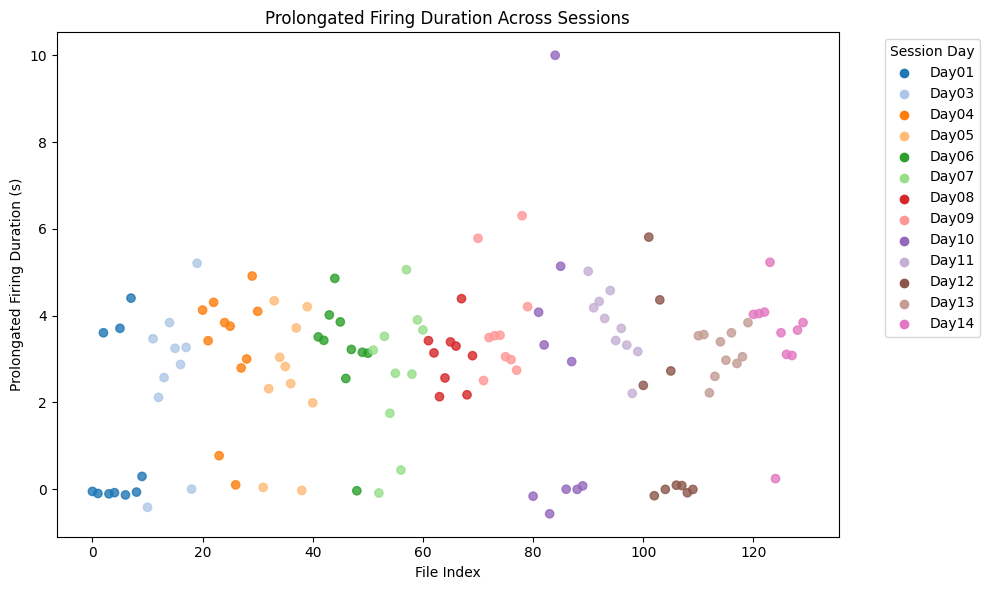

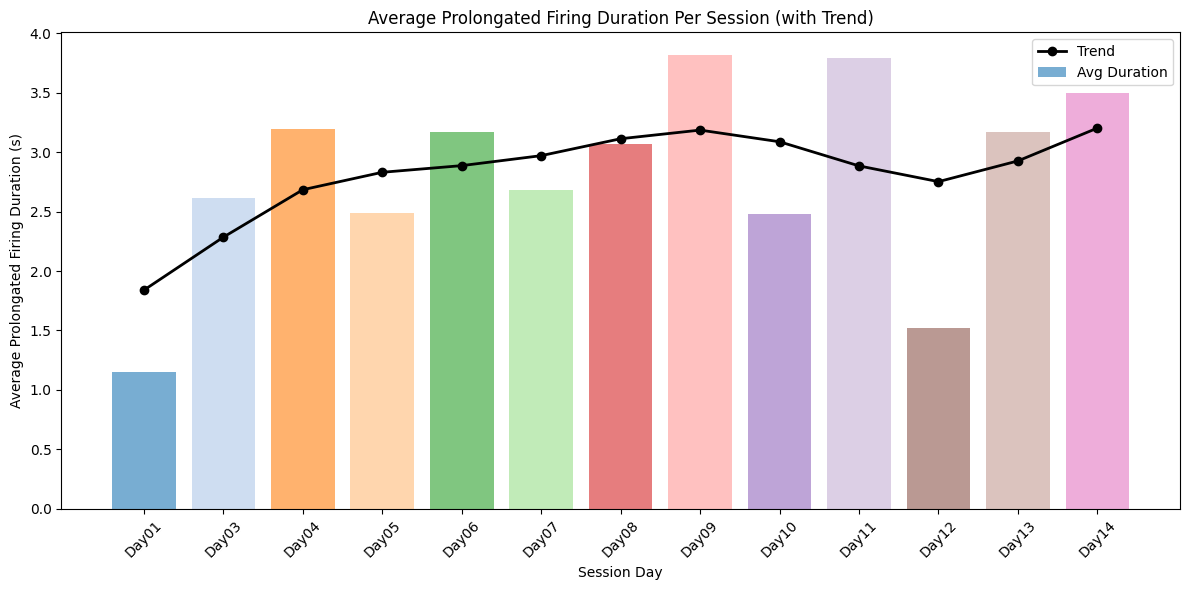

In [255]:
fsamp = 2048  
directory_path = "/Users/nmt121/Desktop/DATA/S1"

# Get all sorted pickle files

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]


num_days = len(session_days)  

if num_days <= 20:
    color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: plt.cm.viridis(i / num_days) for i, day in enumerate(session_days)}

num_files = len(sorted_pkl_files)  
total_dur = []  
colors = []  
day_durations = {day: [] for day in session_days}  

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)  
    with open(file_path, 'rb') as f:
        data = pickle.load(f)  

    data_MU = np.array(data['MU'].tolist())  
    idx_pair = data['Idx_MU_Pair'].tolist()  

    spike_positions_small = np.where(data_MU[idx_pair[0]] == 1)[0]  
    spike_positions_large = np.where(data_MU[idx_pair[1]] == 1)[0]  

    if len(spike_positions_small) == 0 or len(spike_positions_large) == 0:
        continue  

    last_spike_position_small_mn = spike_positions_small[-1]  
    last_spike_position_large_mn = spike_positions_large[-1]  
    
    first_spike_position_small_mn = spike_positions_small[0]  
    first_spike_position_large_mn = spike_positions_large[0]  

    duration_prolongated_firing = (last_spike_position_large_mn - last_spike_position_small_mn) /fsamp #(first_spike_position_small_mn-first_spike_position_large_mn))
    total_dur.append(duration_prolongated_firing)  

    session_day = re.search(r"(Day\d{2})", file_name).group(1) if re.search(r"(Day\d{2})", file_name) else None  
    colors.append(color_map[session_day])  
    day_durations[session_day].append(duration_prolongated_firing)  

day_avg_durations = {day: np.mean(durations) for day, durations in day_durations.items() if durations}  

time = np.arange(len(total_dur))  
plt.figure(figsize=(10, 6))  
plt.scatter(time, total_dur, color=colors, alpha=0.8)  

plt.xlabel("File Index")  
plt.ylabel("Prolongated Firing Duration (s)")  
plt.title("Prolongated Firing Duration Across Sessions")  

for day, color in color_map.items():
    plt.scatter([], [], color=color, label=day)  

plt.legend(title="Session Day", bbox_to_anchor=(1.05, 1), loc='upper left')  
plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/figures/S1.pdf', dpi=300, bbox_inches='tight')  
plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/s3all.pdf', dpi=300, bbox_inches='tight')

plt.show()  

sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))  
sorted_avg_durations = [day_avg_durations[day] for day in sorted_days]  
smoothed_avg_durations = gaussian_filter1d(sorted_avg_durations, sigma=1.2)  

plt.figure(figsize=(12, 6))  
plt.bar(sorted_days, sorted_avg_durations, color=[color_map[day] for day in sorted_days], alpha=0.6, label="Avg Duration")  
plt.plot(sorted_days, smoothed_avg_durations, marker='o', linestyle='-', color='black', linewidth=2, label="Trend")  

plt.xlabel("Session Day")  
plt.ylabel("Average Prolongated Firing Duration (s)")  
plt.title("Average Prolongated Firing Duration Per Session (with Trend)")  

plt.xticks(rotation=45)  
plt.legend()  
plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7neuromod_metric.pdf', dpi=300, bbox_inches='tight')


plt.show()  


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_34295/2324186708.py:54: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


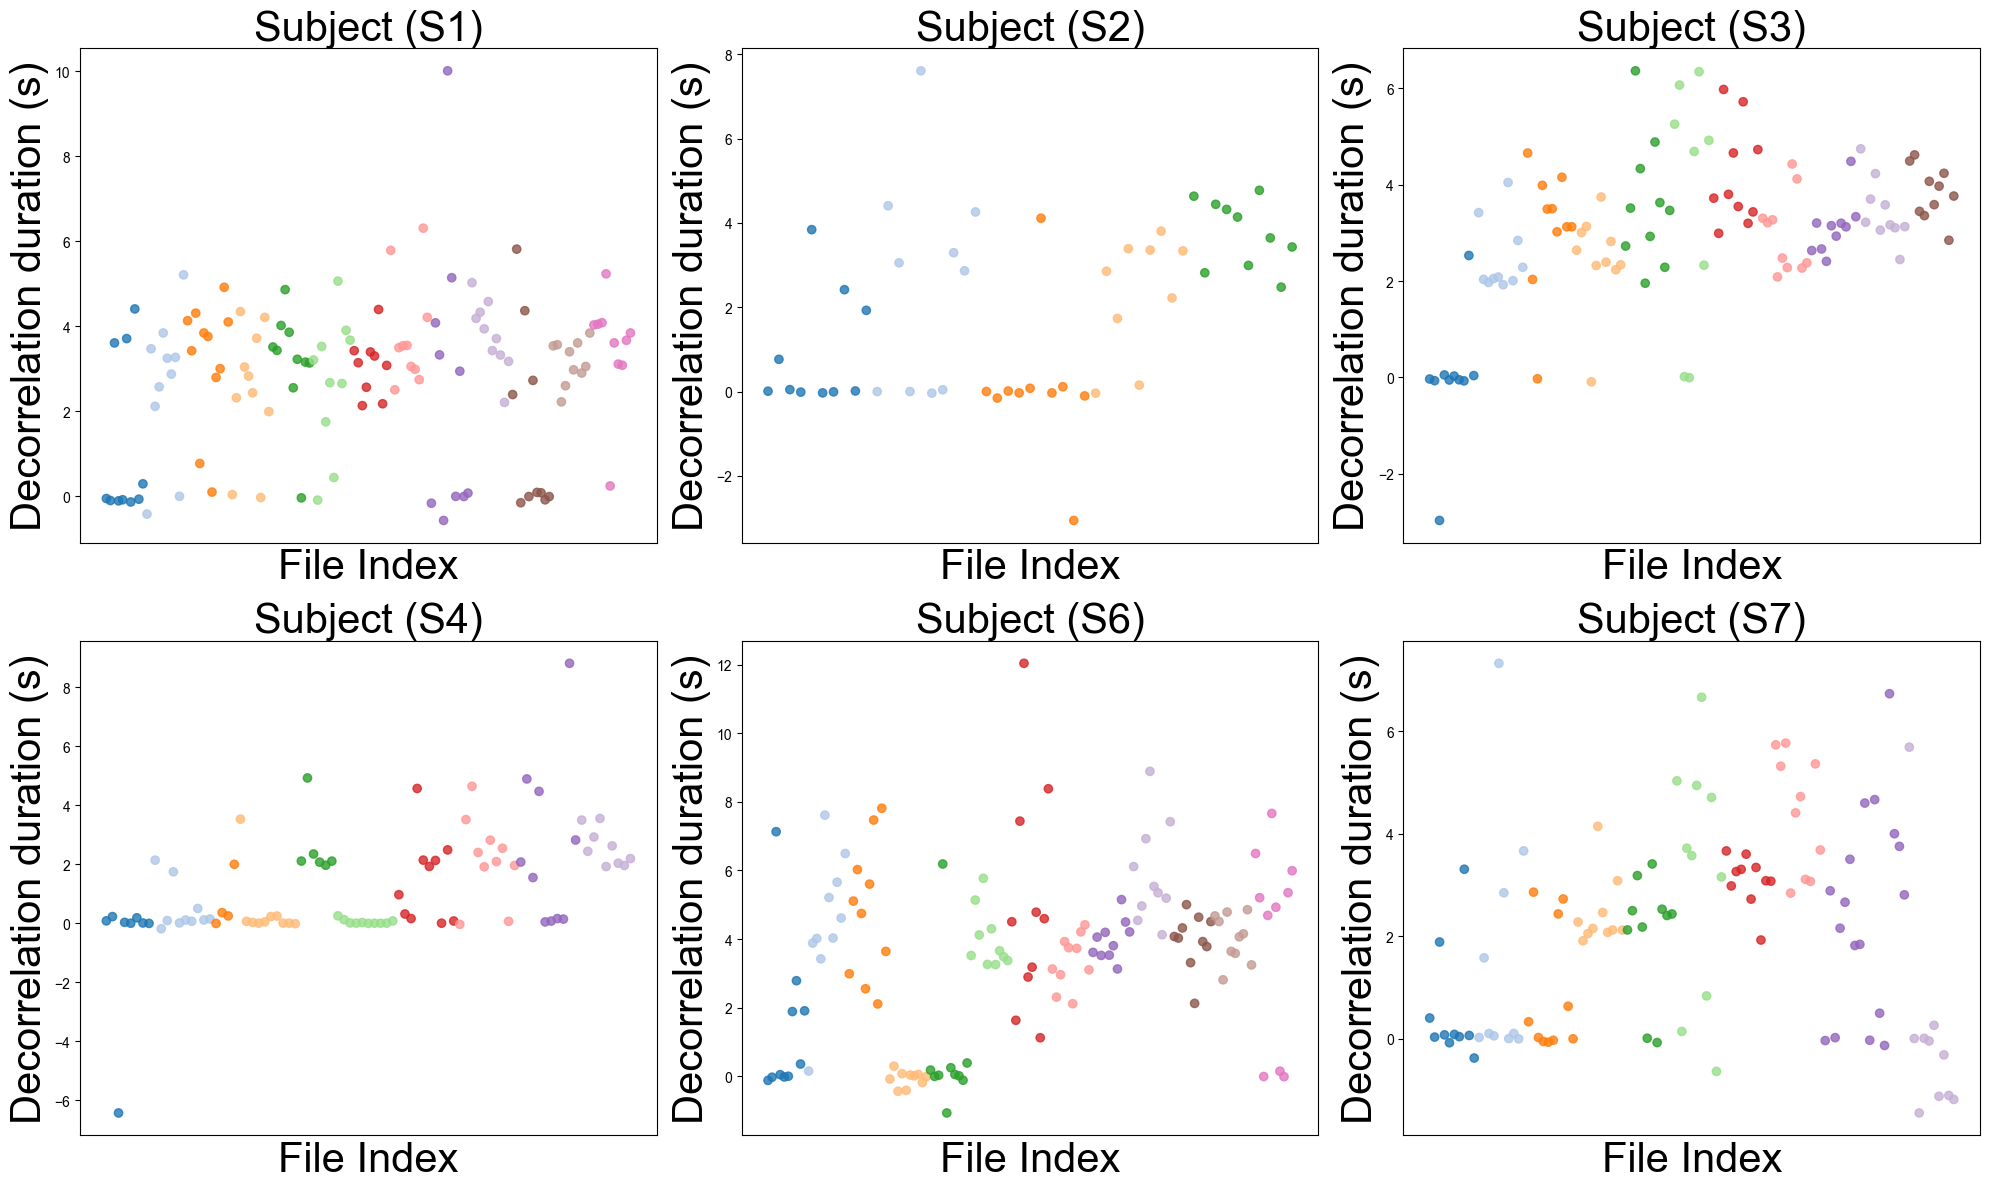

In [133]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
import os
import re
from scipy.ndimage import gaussian_filter1d

subjects = ['S1', 'S2', 'S3', 'S4', 'S6', 'S7']
fsamp = 2048  

# Set up the subplots
fig, axes = plt.subplots(2, 3, figsize=(20, 12))  # 3x2 grid of subplots
axes = axes.flatten()  # Flatten the axes array for easy indexing

# Loop through each subject and create the plot
for idx, subject in enumerate(subjects):
    directory_path = f"/Users/nmt121/Desktop/DATA/{subject}"

    # Extract day from filename
    def extract_day(filename):
        match = re.search(r"(Day\d{2})", filename)
        return match.group(1) if match else None  

    # Extract trial number from filename
    def extract_trial(filename):
        match = re.search(r'_(\d+)[^0-9]', filename)  
        return int(match.group(1)) if match else 0  

    # Get all files and group by day
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    # Create a dictionary grouping files by their respective days
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day:
            if day not in files_by_day:
                files_by_day[day] = []
            files_by_day[day].append(file)

    # Sort the days correctly
    session_days = sorted(files_by_day.keys())

    # Sort files within each day numerically
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    # Flatten the sorted list to get the final ordered file list
    sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

    num_days = len(session_days)  

    if num_days <= 20:
        color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
    else:
        color_map = {day: plt.cm.viridis(i / num_days) for i, day in enumerate(session_days)}

    num_files = len(sorted_pkl_files)  
    total_dur = []  
    colors = []  
    day_durations = {day: [] for day in session_days}  

    for i, file_name in enumerate(sorted_pkl_files):
        file_path = os.path.join(directory_path, file_name)  
        with open(file_path, 'rb') as f:
            data = pickle.load(f)  

        data_MU = np.array(data['MU'].tolist())  
        idx_pair = data['Idx_MU_Pair'].tolist()  

        spike_positions_small = np.where(data_MU[idx_pair[0]] == 1)[0]  
        spike_positions_large = np.where(data_MU[idx_pair[1]] == 1)[0]  

        if len(spike_positions_small) == 0 or len(spike_positions_large) == 0:
            continue  

        last_spike_position_small_mn = spike_positions_small[-1]  
        last_spike_position_large_mn = spike_positions_large[-1]  

        first_spike_position_small_mn = spike_positions_small[0]  
        first_spike_position_large_mn = spike_positions_large[0]  

        duration_prolongated_firing = (last_spike_position_large_mn - last_spike_position_small_mn) / fsamp
        total_dur.append(duration_prolongated_firing)  

        session_day = re.search(r"(Day\d{2})", file_name).group(1) if re.search(r"(Day\d{2})", file_name) else None  
        colors.append(color_map[session_day])  
        day_durations[session_day].append(duration_prolongated_firing)  

    day_avg_durations = {day: np.mean(durations) for day, durations in day_durations.items() if durations}  

    time = np.arange(len(total_dur))  

    # Create the scatter plot for this subject
    ax = axes[idx]
    ax.scatter(time, total_dur, color=colors, alpha=0.8)
    ax.set_xlabel("File Index",fontsize=30)  
    ax.set_ylabel("Decorrelation duration (s)",fontsize=30)    

    ax.set_title(f"Subject ({subject})",fontsize=30)    

    for day, color in color_map.items():
        ax.scatter([], [], color=color, label=day)  

    # ax.legend(title="Session Day", bbox_to_anchor=(1.05, 1), loc='upper left')  
    ax.set_xticks([])  # Remove x-ticks for cleaner view

# Adjust layout and display the plot
plt.tight_layout()  
plt.savefig('/Users/nmt121/Desktop/ALL SUBJECT.pdf', dpi=300, bbox_inches='tight')

plt.show()


## FORCE VS DERIVATIVE OF THE FORCE

In [250]:
# num_files = len(sorted_pkl_files)  
# cols = 6  
# rows = int(np.ceil(num_files / cols))  


# fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))  
# axes = axes.flatten()  

# for i, file_name in enumerate(sorted_pkl_files):  
#     file_path = os.path.join(directory_path, file_name)  
#     with open(file_path, 'rb') as f:  
#         data = pickle.load(f)  

#     force_signal = np.array(data['Force']).flatten()  
#     time_axis = np.arange(len(force_signal)) / fsamp  
#     force_derivative = compute_derivative(force_signal, fsamp)  

#     ax = axes[i]  
#     ax.plot(force_signal, force_derivative, color="blue", alpha=0.8)  
#     ax.set_title(file_name.split('.')[0])  
#     ax.set_xlabel("Force")  
#     ax.set_ylabel("1st Derivative of Force")  

# plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7derivative.pdf', dpi=300, bbox_inches='tight')

# plt.show()  